In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter


# ============================================================
# JOURNAL FIGURE SETTINGS AND DATA
# ============================================================
# All Matplotlib figures use a colour-blind-safe palette, embedded TrueType
# fonts, and 600 dpi export defaults.  The axis-limit helpers below always
# include the complete finite data range; they never clip outliers.

DATA_CANDIDATES = [
    Path("AbaqusSweep/ABaqusData_with_computational_results.csv"),
    Path("../AbaqusSweep/ABaqusData_with_computational_results.csv"),
    Path(r"C:\Users\prz\Documents\HeatXfireDIC\HeatXferDIC\AbaqusSweep\ABaqusData_with_computational_results.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find ABaqusData_with_computational_results.csv")

response_df = pd.read_csv(DATA_PATH)

CURVATURE_COLUMNS = ["K_11", "K_22", "K_12"]
CURVATURE_LABELS = {
    "K_11": r"$\kappa_{11}$",
    "K_22": r"$\kappa_{22}$",
    "K_12": r"$\kappa_{12}$",
}
CURVATURE_AXIS_LABELS = {
    column: f"{label} [m$^{{-1}}$]"
    for column, label in CURVATURE_LABELS.items()
}

JOURNAL_COLORS = {
    "blue": "#0072B2",
    "orange": "#E69F00",
    "green": "#009E73",
    "red": "#D55E00",
    "purple": "#CC79A7",
    "black": "#202020",
    "gray": "#6E6E6E",
}
PLY_COLORS = [
    "#0072B2", "#E69F00", "#009E73", "#CC79A7",
    "#D55E00", "#56B4E9", "#000000",
]

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "axes.linewidth": 0.8,
    "axes.labelpad": 4,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "legend.fontsize": 7,
    "legend.frameon": False,
    "legend.handlelength": 1.5,
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


def finite_values(values):
    """Return finite numeric values as a one-dimensional NumPy array."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def padded_limits(values, *, include_zero=False, symmetric=False, pad=0.06):
    """Compute linear limits that contain every value with a small margin."""
    values = finite_values(values)
    if values.size == 0:
        return (-1.0, 1.0)
    lower, upper = float(values.min()), float(values.max())
    if include_zero:
        lower, upper = min(lower, 0.0), max(upper, 0.0)
    if symmetric:
        extent = max(abs(lower), abs(upper))
        extent = max(extent, np.finfo(float).eps)
        return (-extent * (1 + pad), extent * (1 + pad))
    span = upper - lower
    if np.isclose(span, 0.0):
        span = max(abs(upper), 1.0)
    margin = span * pad
    return (lower - margin, upper + margin)


def equal_physical_limits(*values, pad=0.06):
    """Return one shared numeric range, preserving equal units per axis."""
    combined = np.concatenate([finite_values(value) for value in values])
    lower, upper = padded_limits(combined, pad=pad)
    center = (lower + upper) / 2
    span = upper - lower
    return center - span / 2, center + span / 2


def apply_axis_style(ax, *, integer_x=False):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, axis="y", color="#D9D9D9", linewidth=0.55, zorder=0)
    ax.tick_params(which="both", top=False, right=False)
    if integer_x:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits((-3, 3))
    ax.yaxis.set_major_formatter(formatter)


def set_linear_y_limits(ax, values, *, include_zero=False, symmetric=False):
    ax.set_ylim(*padded_limits(values, include_zero=include_zero, symmetric=symmetric))


def fixed_response_scale(reference, prediction, percentile=95):
    """Stable fixed scale for response-normalized error (not per-case % error)."""
    magnitudes = np.concatenate([finite_values(reference), finite_values(prediction)])
    return max(float(np.nanpercentile(np.abs(magnitudes), percentile)), np.finfo(float).eps)


def plot_grouped_points(ax, data, group_column, value_column, *, color, point_size=14):
    """Jittered observations with median and interquartile-range summaries."""
    groups = sorted(data[group_column].dropna().unique())
    rng = np.random.default_rng(20260911)
    for group in groups:
        values = data.loc[data[group_column] == group, value_column].dropna().to_numpy()
        jitter = rng.uniform(-0.11, 0.11, size=len(values))
        ax.scatter(group + jitter, values, s=point_size, color=color, alpha=0.42,
                   linewidths=0, rasterized=len(values) > 250, zorder=2)
        if len(values):
            q1, median, q3 = np.percentile(values, [25, 50, 75])
            ax.vlines(group, q1, q3, color=JOURNAL_COLORS["black"], linewidth=1.5, zorder=3)
            ax.scatter(group, median, marker="D", s=21, color="white",
                       edgecolor=JOURNAL_COLORS["black"], linewidth=0.7, zorder=4)
    ax.set_xticks(groups)
    ax.set_xlim(min(groups) - 0.5, max(groups) + 0.5)


def case_numbers(data):
    return np.arange(1, len(data) + 1)


print(f"Loaded {len(response_df):,} laminate cases from {DATA_PATH}")


Loaded 545 laminate cases from ..\AbaqusSweep\ABaqusData_with_computational_results.csv


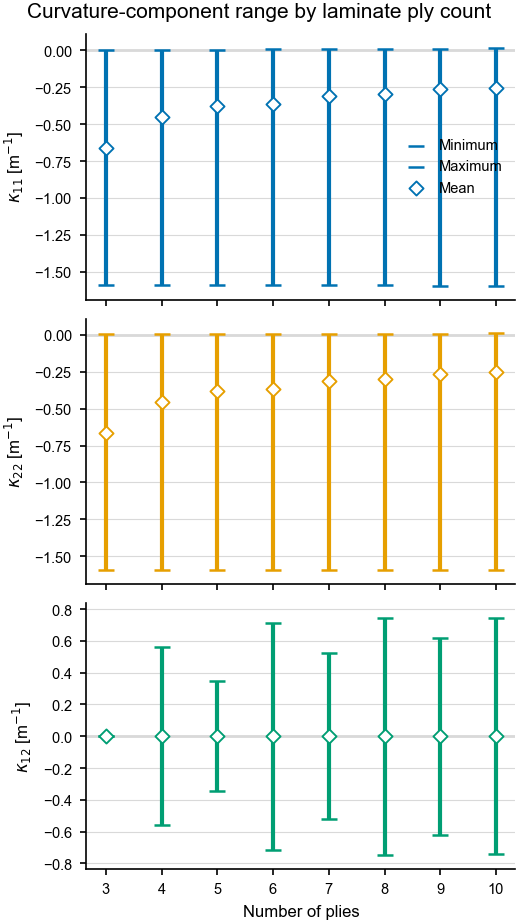

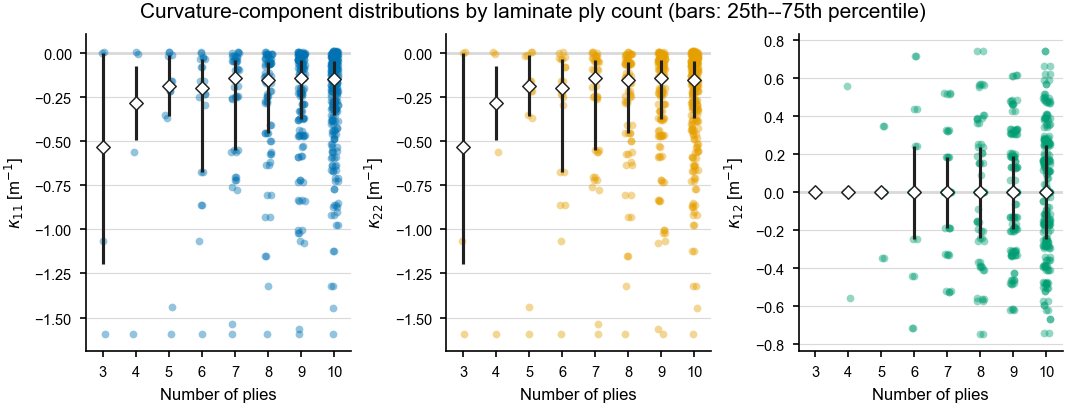

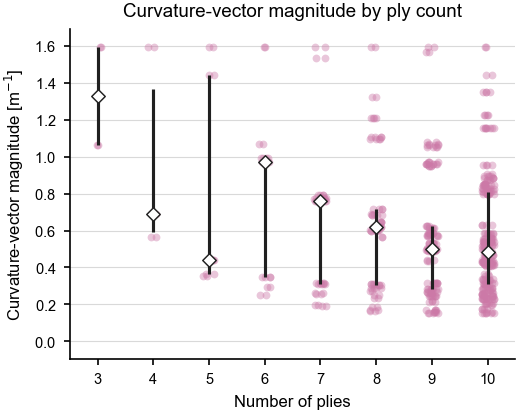

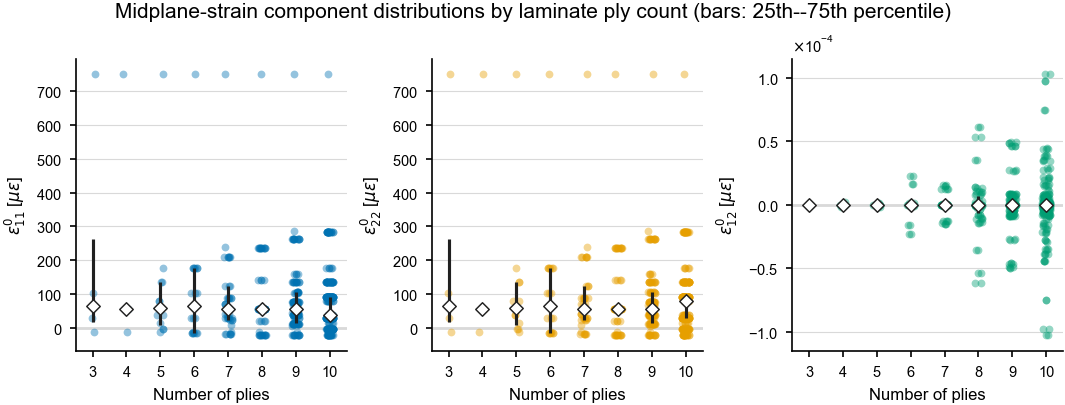

In [2]:
# ============================================================
# CURVATURE RESPONSE BY PLY COUNT
# ============================================================
# Range, distribution, and Euclidean curvature-vector magnitude.  The
# magnitude is explicitly a vector norm, avoiding an unstated tensor-scaling
# convention for the twisting-curvature component.

required_columns = ["NumberOfPlies", *CURVATURE_COLUMNS]
missing = sorted(set(required_columns) - set(response_df.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")

curvature_df = response_df.dropna(subset=required_columns).copy()
ply_counts = sorted(curvature_df["NumberOfPlies"].unique())

# Figure 1: min--max range and mean.
fig, axes = plt.subplots(3, 1, figsize=(3.5, 6.2), sharex=True, layout="constrained")
for ax, component, color in zip(axes, CURVATURE_COLUMNS,
                                [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    grouped = curvature_df.groupby("NumberOfPlies")[component]
    minimum = grouped.min().reindex(ply_counts)
    maximum = grouped.max().reindex(ply_counts)
    mean = grouped.mean().reindex(ply_counts)
    ax.vlines(ply_counts, minimum, maximum, color=color, linewidth=2.0, zorder=2)
    ax.scatter(ply_counts, minimum, marker="_", s=52, color=color, linewidths=1.2,
               label="Minimum" if component == "K_11" else None, zorder=3)
    ax.scatter(ply_counts, maximum, marker="_", s=52, color=color, linewidths=1.2,
               label="Maximum" if component == "K_11" else None, zorder=3)
    ax.scatter(ply_counts, mean, marker="D", s=23, facecolor="white", edgecolor=color,
               linewidth=0.9, label="Mean" if component == "K_11" else None, zorder=4)
    ax.axhline(0, color=JOURNAL_COLORS["gray"], linewidth=0.7, zorder=1)
    ax.set_ylabel(CURVATURE_AXIS_LABELS[component])
    set_linear_y_limits(ax, curvature_df[component], include_zero=True)
    apply_axis_style(ax, integer_x=True)
axes[-1].set_xlabel("Number of plies")
axes[-1].set_xticks(ply_counts)
axes[0].legend(loc="best")
fig.suptitle("Curvature-component range by laminate ply count", fontsize=10)
plt.show()

# Figure 2: all observations plus robust within-group summaries.  The vertical
# bars span the 25th--75th percentiles (IQR); white diamonds mark medians.
fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.75), layout="constrained")
for ax, component, color in zip(axes, CURVATURE_COLUMNS,
                                [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    plot_grouped_points(ax, curvature_df, "NumberOfPlies", component, color=color)
    ax.axhline(0, color=JOURNAL_COLORS["gray"], linewidth=0.7, zorder=1)
    ax.set_ylabel(CURVATURE_AXIS_LABELS[component])
    set_linear_y_limits(ax, curvature_df[component], include_zero=True)
    apply_axis_style(ax, integer_x=True)
for ax in axes:
    ax.set_xlabel("Number of plies")
fig.suptitle("Curvature-component distributions by laminate ply count (bars: 25th--75th percentile)", fontsize=10)
plt.show()

# Figure 3: Euclidean curvature-vector magnitude (all components in m^-1).
curvature_df["CurvatureVectorMagnitude"] = np.linalg.norm(
    curvature_df[CURVATURE_COLUMNS].to_numpy(dtype=float), axis=1
)
fig, ax = plt.subplots(figsize=(3.5, 2.8), layout="constrained")
plot_grouped_points(ax, curvature_df, "NumberOfPlies", "CurvatureVectorMagnitude",
                    color=JOURNAL_COLORS["purple"])
ax.set_xlabel("Number of plies")
ax.set_ylabel(r"Curvature-vector magnitude [m$^{-1}$]")
set_linear_y_limits(ax, curvature_df["CurvatureVectorMagnitude"], include_zero=True)
apply_axis_style(ax, integer_x=True)
ax.set_title("Curvature-vector magnitude by ply count")
plt.show()

# Figure 4: midplane-strain component distributions, in microstrain.
# As above, bars span the 25th--75th percentiles and diamonds mark medians.
STRAIN_COLUMNS = ["e0_11", "e0_22", "e0_12"]
STRAIN_LABELS = {
    "e0_11": r"$\epsilon^0_{11}$ [$\mu\varepsilon$]",
    "e0_22": r"$\epsilon^0_{22}$ [$\mu\varepsilon$]",
    "e0_12": r"$\epsilon^0_{12}$ [$\mu\varepsilon$]",
}
strain_df = response_df.dropna(subset=["NumberOfPlies", *STRAIN_COLUMNS]).copy()
strain_ply_counts = sorted(strain_df["NumberOfPlies"].unique())
for component in STRAIN_COLUMNS:
    strain_df[f"{component}_microstrain"] = strain_df[component] * 1e6

fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.75), layout="constrained")
for ax, component, color in zip(axes, STRAIN_COLUMNS,
                                [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    column = f"{component}_microstrain"
    plot_grouped_points(ax, strain_df, "NumberOfPlies", column, color=color)
    ax.axhline(0, color=JOURNAL_COLORS["gray"], linewidth=0.7, zorder=1)
    ax.set_ylabel(STRAIN_LABELS[component])
    set_linear_y_limits(ax, strain_df[column], include_zero=True)
    apply_axis_style(ax, integer_x=True)
    ax.set_xlabel("Number of plies")
    ax.set_xticks(strain_ply_counts)
fig.suptitle("Midplane-strain component distributions by laminate ply count (bars: 25th--75th percentile)", fontsize=10)
plt.show()


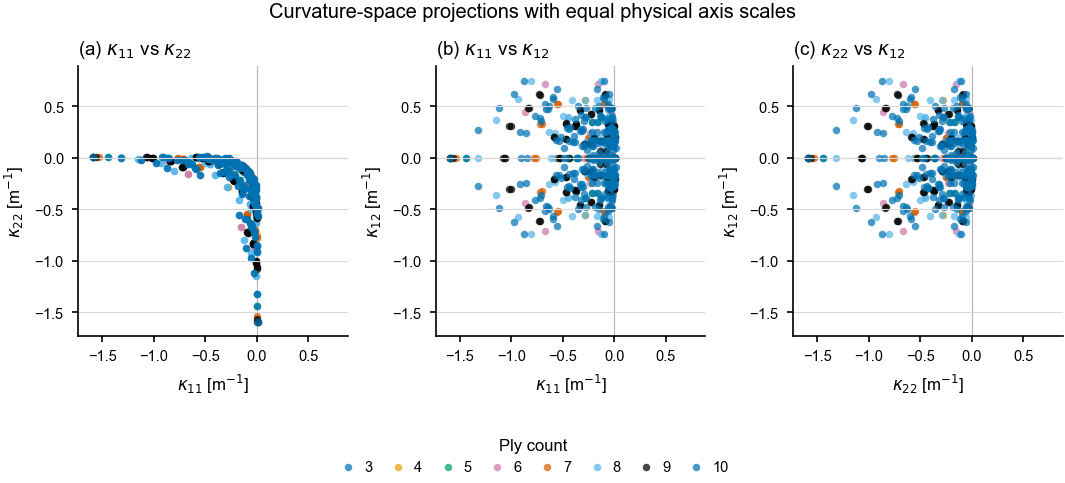

In [3]:
# ============================================================
# MANUSCRIPT-READY CURVATURE-SPACE PROJECTIONS
# ============================================================
# Orthographic pairwise projections are preferred over a perspective 3-D
# graphic in a manuscript.  The common limits and equal aspect ratio mean one
# plotted unit represents the same curvature on every horizontal/vertical axis.

plot_df = response_df.dropna(subset=["NumberOfPlies", *CURVATURE_COLUMNS]).copy()
plot_df["Ply count"] = plot_df["NumberOfPlies"].astype(int).astype(str)
ply_labels = sorted(plot_df["Ply count"].unique(), key=int)
color_map = {label: PLY_COLORS[index % len(PLY_COLORS)] for index, label in enumerate(ply_labels)}
component_limits = equal_physical_limits(*(plot_df[column] for column in CURVATURE_COLUMNS))

pairs = [("K_11", "K_22"), ("K_11", "K_12"), ("K_22", "K_12")]
panel_labels = ["(a)", "(b)", "(c)"]
fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.65), layout="constrained")
for ax, (x_column, y_column), panel_label in zip(axes, pairs, panel_labels):
    for ply_label in ply_labels:
        subset = plot_df[plot_df["Ply count"] == ply_label]
        ax.scatter(subset[x_column], subset[y_column], s=13, alpha=0.72,
                   color=color_map[ply_label], linewidths=0, label=ply_label,
                   rasterized=len(plot_df) > 250)
    ax.axhline(0, color="#B5B5B5", linewidth=0.55, zorder=0)
    ax.axvline(0, color="#B5B5B5", linewidth=0.55, zorder=0)
    ax.set_xlim(component_limits)
    ax.set_ylim(component_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(CURVATURE_AXIS_LABELS[x_column])
    ax.set_ylabel(CURVATURE_AXIS_LABELS[y_column])
    ax.set_title(f"{panel_label} {CURVATURE_LABELS[x_column]} vs {CURVATURE_LABELS[y_column]}", loc="left")
    apply_axis_style(ax)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Ply count", ncol=len(ply_labels), loc="lower center",
           bbox_to_anchor=(0.5, -0.20), columnspacing=1.0, handletextpad=0.35)
fig.suptitle("Curvature-space projections with equal physical axis scales", y=1.02)
plt.show()


In [4]:
# ============================================================
# INTERACTIVE 3-D CURVATURE AND MIDPLANE-STRAIN SPACE
# ============================================================
# These interactive views are useful supplementary figures.  Both scenes use
# equal numerical ranges and a cubic aspect ratio, so units are not distorted
# by the 3-D rendering.  Use the static projections in the preceding cell in
# the manuscript itself.

import plotly.express as px

interactive_df = response_df.dropna(subset=["NumberOfPlies", *CURVATURE_COLUMNS,
                                            "e0_11", "e0_22", "e0_12"]).copy()
interactive_df["Ply count"] = interactive_df["NumberOfPlies"].astype(int).astype(str)
interactive_df["e0_11_microstrain"] = interactive_df["e0_11"] * 1e6
interactive_df["e0_22_microstrain"] = interactive_df["e0_22"] * 1e6
interactive_df["e0_12_microstrain"] = interactive_df["e0_12"] * 1e6


def equal_scene_ranges(data, columns, pad=0.025):
    """Per-axis ranges with an identical numerical span for undistorted units."""
    limits = equal_physical_limits(*(data[column] for column in columns), pad=pad)
    center_span = limits[1] - limits[0]
    ranges = {}
    for column in columns:
        midpoint = (data[column].min() + data[column].max()) / 2
        ranges[column] = [midpoint - center_span / 2, midpoint + center_span / 2]
    return ranges


def publication_3d(data, columns, labels, title, camera, *, shaded_plotly_scene=False):
    ranges = equal_scene_ranges(data, columns)
    if shaded_plotly_scene:
        color_sequence = px.colors.qualitative.Plotly
        template = "plotly"
        scene_style = {"showbackground": True, "backgroundcolor": "#E5ECF6",
                       "gridcolor": "#FFFFFF", "zerolinecolor": "#FFFFFF"}
    else:
        color_sequence = PLY_COLORS
        template = "simple_white"
        scene_style = {"showbackground": False, "gridcolor": "#D9D9D9",
                       "zerolinecolor": "#8C8C8C"}
    fig = px.scatter_3d(
        data,
        x=columns[0], y=columns[1], z=columns[2], color="Ply count",
        hover_data={"NumberOfPlies": True, "Layup": True},
        labels={**labels, "Ply count": "Number of plies"},
        color_discrete_sequence=color_sequence,
        category_orders={"Ply count": sorted(data["Ply count"].unique(), key=int)},
        title=title,
    )
    fig.update_traces(marker={"size": 6, "opacity": 0.82, "line": {"width": 0}})
    fig.update_layout(
        template=template, width=1400, height=1020,
        font={"family": "Arial", "size": 18, "color": "#202020"},
        title={"font": {"size": 28}},
        legend={"title": {"text": "Number of plies", "font": {"size": 21}},
                "font": {"size": 18}, "itemsizing": "constant"},
        margin={"l": 15, "r": 15, "t": 70, "b": 15},
    )
    fig.update_scenes(
        aspectmode="cube",
        camera=camera,
        xaxis={"title": labels[columns[0]], "range": ranges[columns[0]], **scene_style,
               "title": {"font": {"size": 24}}, "tickfont": {"size": 17}},
        yaxis={"title": labels[columns[1]], "range": ranges[columns[1]], **scene_style,
               "title": {"font": {"size": 24}}, "tickfont": {"size": 17}},
        zaxis={"title": labels[columns[2]], "range": ranges[columns[2]], **scene_style,
               "title": {"font": {"size": 24}}, "tickfont": {"size": 17}},
    )
    return fig


fig_curvature = publication_3d(
    interactive_df,
    ["K_11", "K_22", "K_12"],
    {"K_11": "κ₁₁ [m⁻¹]", "K_22": "κ₂₂ [m⁻¹]", "K_12": "κ₁₂ [m⁻¹]"},
    "(a) Curvature space by laminate ply count",
    # Shared front-corner view: K_22/e0_22 at lower left, K_11/e0_11 at
    # lower right, and the 12 component vertical, matching the paper view.
    camera={"eye": {"x": 1.05, "y": 1.05, "z": 0.80},
            "center": {"x": 0, "y": 0, "z": 0}, "up": {"x": 0, "y": 0, "z": 1}},
)
fig_curvature.show()

fig_strain = publication_3d(
    interactive_df,
    ["e0_11_microstrain", "e0_22_microstrain", "e0_12_microstrain"],
    {"e0_11_microstrain": "ε⁰₁₁ [µε]", "e0_22_microstrain": "ε⁰₂₂ [µε]",
     "e0_12_microstrain": "ε⁰₁₂ [µε]"},
    "(b) Midplane strain space by laminate ply count",
    # Use the identical axis-aligned front-corner view for direct comparison.
    camera={"eye": {"x": 1.05, "y": 1.05, "z": 0.80},
            "center": {"x": 0, "y": 0, "z": 0}, "up": {"x": 0, "y": 0, "z": 1}},
)
fig_strain.show()

# Styled Plotly variants: same data, limits, and camera as above, but with
# shaded panes and Plotly's categorical palette for a direct comparison.
fig_curvature_plotly = publication_3d(
    interactive_df,
    ["K_11", "K_22", "K_12"],
    {"K_11": "Îºâ‚â‚ [mâ»Â¹]", "K_22": "Îºâ‚‚â‚‚ [mâ»Â¹]", "K_12": "Îºâ‚â‚‚ [mâ»Â¹]"},
    "(a) Curvature space by laminate ply count — shaded Plotly scene",
    camera={"eye": {"x": 1.05, "y": 1.05, "z": 0.80},
            "center": {"x": 0, "y": 0, "z": 0}, "up": {"x": 0, "y": 0, "z": 1}},
    shaded_plotly_scene=True,
)
fig_curvature_plotly.show()

fig_strain_plotly = publication_3d(
    interactive_df,
    ["e0_11_microstrain", "e0_22_microstrain", "e0_12_microstrain"],
    {"e0_11_microstrain": "Îµâ°â‚â‚ [ÂµÎµ]", "e0_22_microstrain": "Îµâ°â‚‚â‚‚ [ÂµÎµ]",
     "e0_12_microstrain": "Îµâ°â‚â‚‚ [ÂµÎµ]"},
    "(b) Midplane strain space by laminate ply count — shaded Plotly scene",
    camera={"eye": {"x": 1.05, "y": 1.05, "z": 0.80},
            "center": {"x": 0, "y": 0, "z": 0}, "up": {"x": 0, "y": 0, "z": 1}},
    shaded_plotly_scene=True,
)
fig_strain_plotly.show()


,Component,Fixed response scale [m⁻¹],MAE [m⁻¹],Median fixed-scale error [%],Maximum fixed-scale error [%]
0,$\kappa_{11}$,0.9745,0.0005153,0.0373,0.312
1,$\kappa_{22}$,0.9745,0.0005153,0.0384,0.312
2,$\kappa_{12}$,0.6105,0.0007318,0.0667,0.61


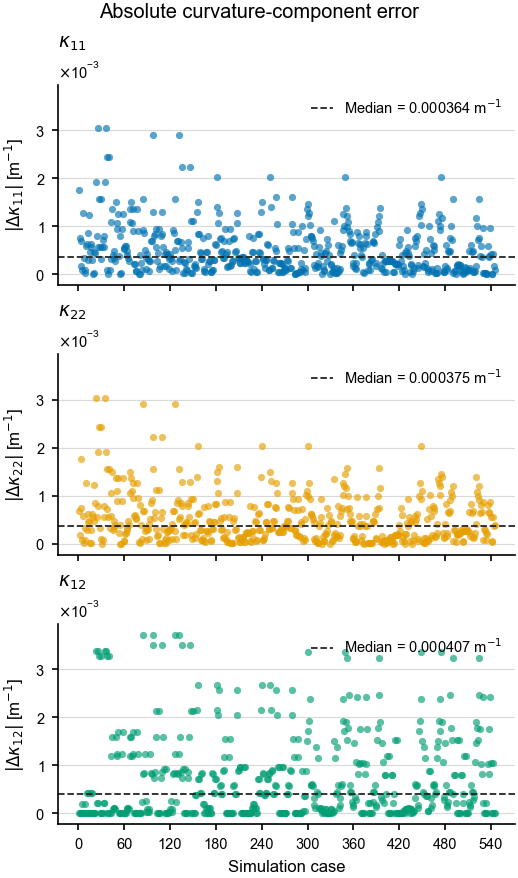

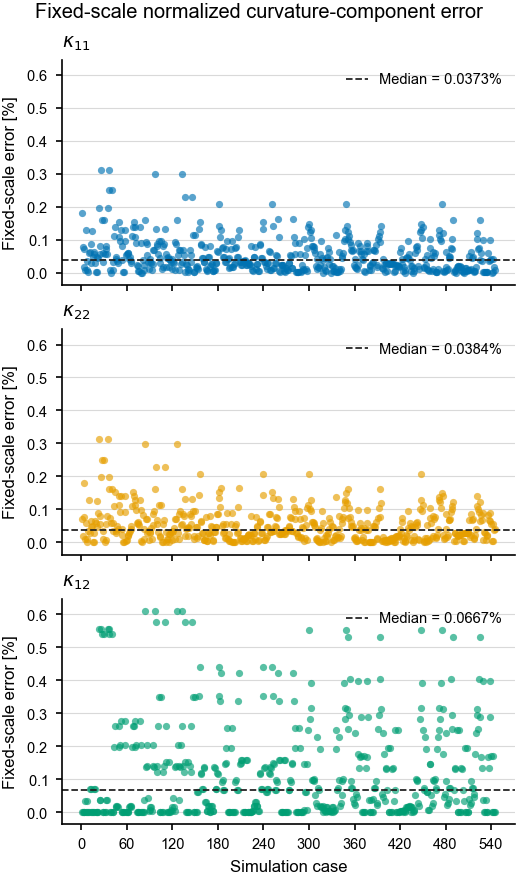

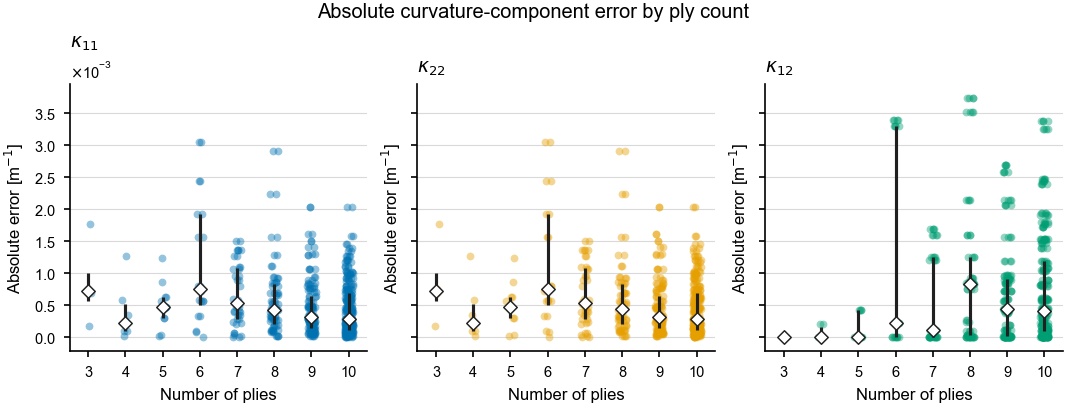

In [5]:
# ============================================================
# COMPONENT-WISE FEA--COMPUTATIONAL ERROR
# ============================================================
# The normalized metric is an absolute error divided by a fixed 95th-percentile
# response scale for that component.  It remains well defined near zero, unlike
# conventional per-case percentage error.

FEA_COLUMNS = {"K11": "K_11", "K22": "K_22", "K12": "K_12"}
COMPUTATIONAL_COLUMNS = {"K11": "Comp_K_11", "K22": "Comp_K_22", "K12": "Comp_K_12"}
components = list(FEA_COLUMNS)

error_df = response_df.dropna(subset=[*FEA_COLUMNS.values(), *COMPUTATIONAL_COLUMNS.values()]).copy()
component_summary_rows = []
for component in components:
    fea_column = FEA_COLUMNS[component]
    comp_column = COMPUTATIONAL_COLUMNS[component]
    absolute_column = f"{component}_AbsoluteError"
    normalized_column = f"{component}_FixedScaleErrorPercent"
    scale = fixed_response_scale(error_df[fea_column], error_df[comp_column])
    error_df[absolute_column] = (error_df[fea_column] - error_df[comp_column]).abs()
    error_df[normalized_column] = 100 * error_df[absolute_column] / scale
    component_summary_rows.append({
        "Component": CURVATURE_LABELS[fea_column],
        "Fixed response scale [m⁻¹]": scale,
        "MAE [m⁻¹]": error_df[absolute_column].mean(),
        "Median fixed-scale error [%]": error_df[normalized_column].median(),
        "Maximum fixed-scale error [%]": error_df[normalized_column].max(),
    })

component_error_summary = pd.DataFrame(component_summary_rows)
display(component_error_summary.style.format({
    "Fixed response scale [m⁻¹]": "{:.4g}", "MAE [m⁻¹]": "{:.4g}",
    "Median fixed-scale error [%]": "{:.3g}", "Maximum fixed-scale error [%]": "{:.3g}",
}))

case_id = case_numbers(error_df)
absolute_columns = [f"{component}_AbsoluteError" for component in components]
normalized_columns = [f"{component}_FixedScaleErrorPercent" for component in components]
component_error_labels = {
    "K11": r"$|\Delta \kappa_{11}|$ [m$^{-1}$]",
    "K22": r"$|\Delta \kappa_{22}|$ [m$^{-1}$]",
    "K12": r"$|\Delta \kappa_{12}|$ [m$^{-1}$]",
}

# Figure 1: absolute component errors.  Common vertical scale permits direct comparison.
fig, axes = plt.subplots(3, 1, figsize=(3.5, 5.9), sharex=True, sharey=True, layout="constrained")
common_absolute = error_df[absolute_columns].to_numpy()
for ax, component, column, color in zip(axes, components, absolute_columns,
                                        [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    values = error_df[column]
    median = values.median()
    ax.scatter(case_id, values, s=12, alpha=0.65, color=color, linewidths=0, rasterized=True, zorder=2)
    ax.axhline(median, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.85,
               label=rf"Median = {median:.3g} m$^{{-1}}$")
    ax.set_ylabel(component_error_labels[component])
    ax.set_title(CURVATURE_LABELS[FEA_COLUMNS[component]], loc="left")
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="upper right")
for ax in axes:
    set_linear_y_limits(ax, common_absolute, include_zero=True)
axes[-1].set_xlabel("Simulation case")
fig.suptitle("Absolute curvature-component error")
plt.show()

# Figure 2: stable, fixed-scale normalized component errors.
fig, axes = plt.subplots(3, 1, figsize=(3.5, 5.9), sharex=True, sharey=True, layout="constrained")
common_normalized = error_df[normalized_columns].to_numpy()
for ax, component, column, color in zip(axes, components, normalized_columns,
                                        [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    values = error_df[column]
    median = values.median()
    ax.scatter(case_id, values, s=12, alpha=0.65, color=color, linewidths=0, rasterized=True, zorder=2)
    ax.axhline(median, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.85,
               label=f"Median = {median:.3g}%")
    ax.set_ylabel("Fixed-scale error [%]")
    ax.set_title(CURVATURE_LABELS[FEA_COLUMNS[component]], loc="left")
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="upper right")
for ax in axes:
    set_linear_y_limits(ax, common_normalized, include_zero=True)
axes[-1].set_xlabel("Simulation case")
fig.suptitle("Fixed-scale normalized curvature-component error")
plt.show()

# Figure 3: error distributions by ply count, with median and IQR overlays.
fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.75), sharey=True, layout="constrained")
for ax, component, column, color in zip(axes, components, absolute_columns,
                                        [JOURNAL_COLORS["blue"], JOURNAL_COLORS["orange"], JOURNAL_COLORS["green"]]):
    plot_grouped_points(ax, error_df, "NumberOfPlies", column, color=color)
    ax.set_ylabel("Absolute error [m$^{-1}$]")
    ax.set_title(CURVATURE_LABELS[FEA_COLUMNS[component]], loc="left")
    apply_axis_style(ax, integer_x=True)
for ax in axes:
    set_linear_y_limits(ax, common_absolute, include_zero=True)
for ax in axes:
    ax.set_xlabel("Number of plies")
fig.suptitle("Absolute curvature-component error by ply count")
plt.show()


,Fixed vector response scale [m⁻¹],MAE [m⁻¹],Median fixed-scale error [%],Maximum fixed-scale error [%]
0,1.348,0.001127,0.06076,0.3691


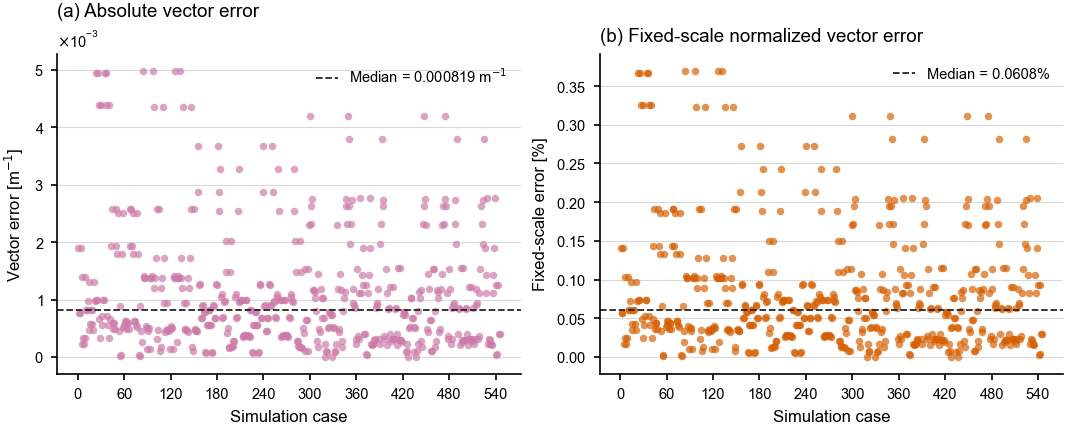

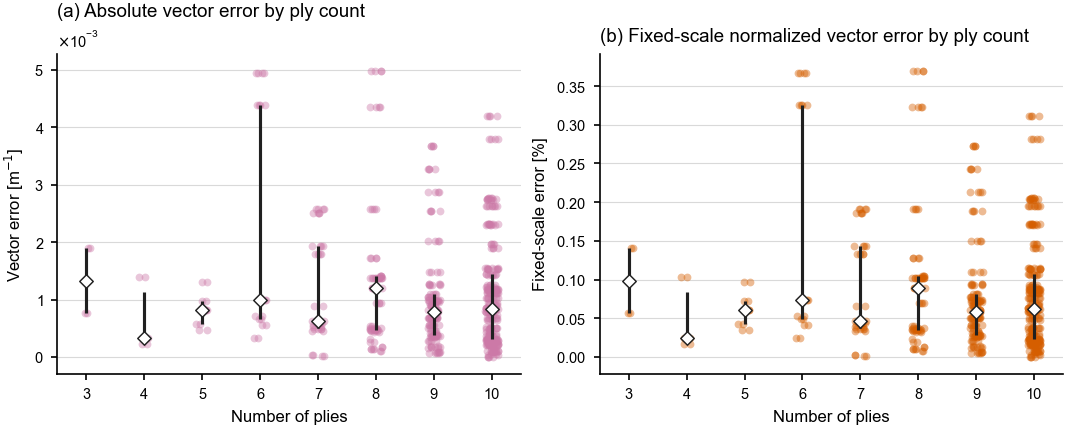

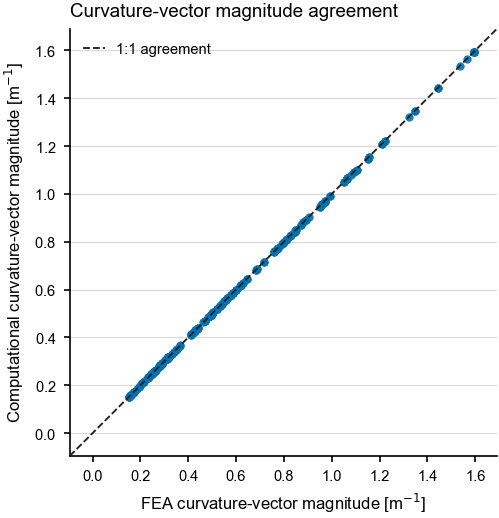

In [6]:
# ============================================================
# COMBINED CURVATURE-VECTOR ERROR
# ============================================================
# This is a Euclidean norm of the three reported curvature components.  It is
# labelled as a vector metric so no tensor-scaling convention is implied.

curvature_fea = error_df[["K_11", "K_22", "K_12"]].to_numpy(dtype=float)
curvature_comp = error_df[["Comp_K_11", "Comp_K_22", "Comp_K_12"]].to_numpy(dtype=float)
error_df["FEACurvatureVectorMagnitude"] = np.linalg.norm(curvature_fea, axis=1)
error_df["ComputationalCurvatureVectorMagnitude"] = np.linalg.norm(curvature_comp, axis=1)
error_df["CurvatureVectorAbsoluteError"] = np.linalg.norm(curvature_fea - curvature_comp, axis=1)
vector_scale = fixed_response_scale(error_df["FEACurvatureVectorMagnitude"],
                                    error_df["ComputationalCurvatureVectorMagnitude"])
error_df["CurvatureVectorFixedScaleErrorPercent"] = (
    100 * error_df["CurvatureVectorAbsoluteError"] / vector_scale
)

vector_summary = pd.DataFrame([{
    "Fixed vector response scale [m⁻¹]": vector_scale,
    "MAE [m⁻¹]": error_df["CurvatureVectorAbsoluteError"].mean(),
    "Median fixed-scale error [%]": error_df["CurvatureVectorFixedScaleErrorPercent"].median(),
    "Maximum fixed-scale error [%]": error_df["CurvatureVectorFixedScaleErrorPercent"].max(),
}])
display(vector_summary.style.format("{:.4g}"))

case_id = case_numbers(error_df)
fig, axes = plt.subplots(1, 2, figsize=(7.15, 2.9), layout="constrained")
plot_specs = [
    ("CurvatureVectorAbsoluteError", r"Vector error [m$^{-1}$]", "Absolute vector error", JOURNAL_COLORS["purple"]),
    ("CurvatureVectorFixedScaleErrorPercent", "Fixed-scale error [%]", "Fixed-scale normalized vector error", JOURNAL_COLORS["red"]),
]
for ax, (column, ylabel, title, color), panel in zip(axes, plot_specs, ["(a)", "(b)"]):
    values = error_df[column]
    median = values.median()
    ax.scatter(case_id, values, s=13, alpha=0.68, color=color, linewidths=0, rasterized=True, zorder=2)
    unit_suffix = "%" if "%" in ylabel else r" m$^{-1}$"
    ax.axhline(median, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.85,
               label=f"Median = {median:.3g}{unit_suffix}")
    ax.set_xlabel("Simulation case")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{panel} {title}", loc="left")
    set_linear_y_limits(ax, values, include_zero=True)
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="upper right")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(7.15, 2.9), layout="constrained")
for ax, (column, ylabel, title, color), panel in zip(axes, plot_specs, ["(a)", "(b)"]):
    plot_grouped_points(ax, error_df, "NumberOfPlies", column, color=color)
    ax.set_xlabel("Number of plies")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{panel} {title} by ply count", loc="left")
    set_linear_y_limits(ax, error_df[column], include_zero=True)
    apply_axis_style(ax, integer_x=True)
plt.show()

# Agreement plot: identical x/y limits and equal aspect make the 1:1 line valid.
agreement_values = np.concatenate([
    error_df["FEACurvatureVectorMagnitude"].to_numpy(),
    error_df["ComputationalCurvatureVectorMagnitude"].to_numpy(),
])
agreement_limits = padded_limits(agreement_values, include_zero=True)
fig, ax = plt.subplots(figsize=(3.5, 3.5), layout="constrained")
ax.scatter(error_df["FEACurvatureVectorMagnitude"], error_df["ComputationalCurvatureVectorMagnitude"],
           s=15, alpha=0.70, color=JOURNAL_COLORS["blue"], linewidths=0, rasterized=True, zorder=2)
ax.plot(agreement_limits, agreement_limits, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.9,
        label="1:1 agreement", zorder=3)
ax.set_xlim(agreement_limits)
ax.set_ylim(agreement_limits)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"FEA curvature-vector magnitude [m$^{-1}$]")
ax.set_ylabel(r"Computational curvature-vector magnitude [m$^{-1}$]")
ax.set_title("Curvature-vector magnitude agreement", loc="left")
apply_axis_style(ax)
ax.legend(loc="upper left")
plt.show()


,Layup,Position45,K_11,K_22,K_12
1,[45/0/0/0/0/0/0/0],1.0,-0.115877,-0.796399,0.813963
2,[0/45/0/0/0/0/0/0],2.0,-0.067334,-0.952886,0.694642
3,[0/0/45/0/0/0/0/0],3.0,-0.028554,-1.178806,0.528991
4,[0/0/0/45/0/0/0/0],4.0,0.002794,-1.454245,0.221248
5,[0/0/0/0/45/0/0/0],5.0,0.005039,-1.680804,-0.146291
6,[0/0/0/0/0/45/0/0],6.0,-0.000268,-1.756928,-0.268272
7,[0/0/0/0/0/0/45/0],7.0,0.003578,-1.708579,-0.192201
8,[0/0/0/0/0/0/0/45],8.0,0.006948,-1.612174,-0.029276


,Layup,Position90,K_11,K_22,K_12
9,[90/0/0/0/0/0/0/0],1.0,-0.062005,0.442760,1.033626e-11
10,[0/90/0/0/0/0/0/0],2.0,-0.059603,0.154291,6.495233e-12
11,[0/0/90/0/0/0/0/0],3.0,-0.016198,-0.367985,5.230330e-12
12,[0/0/0/90/0/0/0/0],4.0,0.003247,-1.166130,-9.323274e-13
13,[0/0/0/0/90/0/0/0],5.0,0.008937,-1.853222,8.958401e-13
14,[0/0/0/0/90/0/0/0],5.0,0.008937,-1.853222,8.958401e-13
15,[0/0/0/0/0/90/0/0],6.0,0.010554,-2.073019,1.915154e-13
16,[0/0/0/0/0/0/90/0],7.0,0.009884,-1.922307,7.109269e-12
17,[0/0/0/0/0/0/0/90],8.0,0.006976,-1.651255,-1.884814e-12


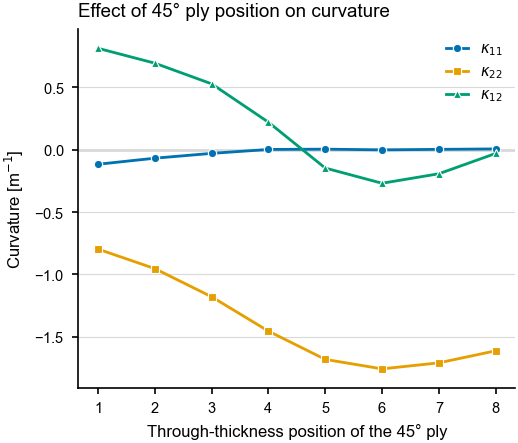

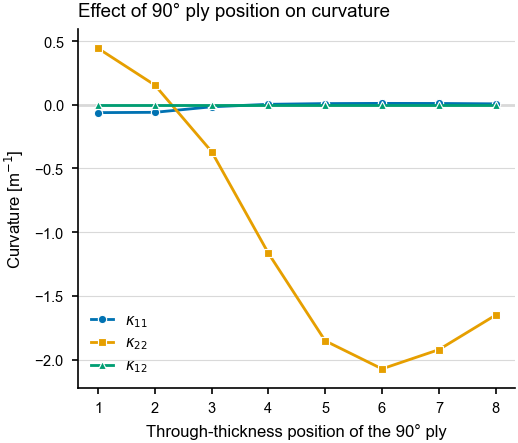

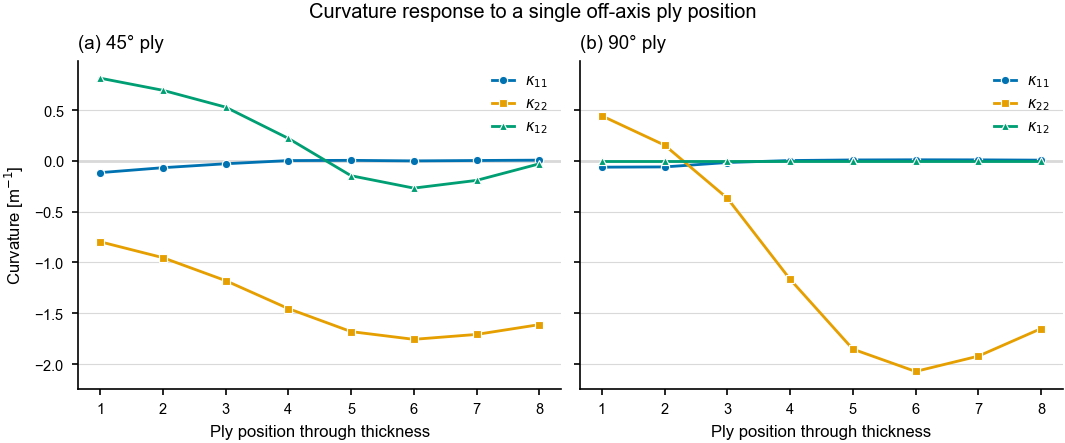

In [7]:
# ============================================================
# EFFECT OF A SINGLE 45° OR 90° PLY THROUGH THE THICKNESS
# ============================================================
# Component-specific panels prevent the larger κ22 response from visually
# suppressing the κ11 and κ12 trends.  Comparison panels share limits by row.

LAYER_DATA_CANDIDATES = [
    Path("LayupSweep/LayerEffect.csv"),
    Path("../LayupSweep/LayerEffect.csv"),
    Path(r"C:\Users\prz\Documents\HeatXfireDIC\HeatXferDIC\LayupSweep\LayerEffect.csv"),
]
LAYER_DATA_PATH = next((path for path in LAYER_DATA_CANDIDATES if path.exists()), None)
if LAYER_DATA_PATH is None:
    raise FileNotFoundError("Could not find LayerEffect.csv")

layer_df = pd.read_csv(LAYER_DATA_PATH)


def parse_layup(layup):
    return [float(value) for value in str(layup).strip().strip("[]").split("/")]


def unique_angle_position(layup, angle):
    matches = [index for index, value in enumerate(layup) if np.isclose(value, angle)]
    return matches[0] + 1 if len(matches) == 1 else np.nan


layer_df["LayupList"] = layer_df["Layup"].apply(parse_layup)
layer_df["Position45"] = layer_df["LayupList"].apply(lambda layup: unique_angle_position(layup, 45))
layer_df["Position90"] = layer_df["LayupList"].apply(lambda layup: unique_angle_position(layup, 90))
sweep45 = layer_df.dropna(subset=["Position45"]).sort_values("Position45").copy()
sweep90 = layer_df.dropna(subset=["Position90"]).sort_values("Position90").copy()

display(sweep45[["Layup", "Position45", *CURVATURE_COLUMNS]])
display(sweep90[["Layup", "Position90", *CURVATURE_COLUMNS]])


def plot_single_position_sweep(data, position_column, angle_label, color):
    """Overlay all curvature components for one off-axis-ply position sweep."""
    fig, ax = plt.subplots(figsize=(3.5, 3.0), layout="constrained")
    markers = {"K_11": "o", "K_22": "s", "K_12": "^"}
    colors = {"K_11": JOURNAL_COLORS["blue"], "K_22": JOURNAL_COLORS["orange"],
              "K_12": JOURNAL_COLORS["green"]}
    for component in CURVATURE_COLUMNS:
        ax.plot(data[position_column], data[component], marker=markers[component], markersize=4,
                linewidth=1.35, color=colors[component], markeredgecolor="white",
                markeredgewidth=0.55, label=CURVATURE_LABELS[component], zorder=2)
    ax.axhline(0, color=JOURNAL_COLORS["gray"], linewidth=0.7, zorder=1)
    ax.set_xlabel(f"Through-thickness position of the {angle_label} ply")
    ax.set_ylabel(r"Curvature [m$^{-1}$]")
    ax.set_title(f"Effect of {angle_label} ply position on curvature", loc="left")
    position_values = data[position_column].astype(int)
    ax.set_xticks(range(position_values.min(), position_values.max() + 1))
    set_linear_y_limits(ax, data[CURVATURE_COLUMNS].to_numpy(), include_zero=True)
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="best")
    plt.show()


plot_single_position_sweep(sweep45, "Position45", "45°", JOURNAL_COLORS["blue"])
plot_single_position_sweep(sweep90, "Position90", "90°", JOURNAL_COLORS["orange"])

# Direct comparison: every panel shows all three components and both panels
# use one shared vertical scale for a valid 45°/90° comparison.
comparison_values = np.concatenate([
    sweep45[CURVATURE_COLUMNS].to_numpy().ravel(),
    sweep90[CURVATURE_COLUMNS].to_numpy().ravel(),
])
comparison_limits = padded_limits(comparison_values, include_zero=True)
fig, axes = plt.subplots(1, 2, figsize=(7.15, 3.0), sharey=True, layout="constrained")
markers = {"K_11": "o", "K_22": "s", "K_12": "^"}
colors = {"K_11": JOURNAL_COLORS["blue"], "K_22": JOURNAL_COLORS["orange"],
          "K_12": JOURNAL_COLORS["green"]}
for ax, data, position_column, title, panel in zip(
    axes,
    [sweep45, sweep90],
    ["Position45", "Position90"],
    ["45° ply", "90° ply"],
    ["(a)", "(b)"],
):
    for component in CURVATURE_COLUMNS:
        ax.plot(data[position_column], data[component], marker=markers[component], markersize=4,
                linewidth=1.35, color=colors[component], markeredgecolor="white",
                markeredgewidth=0.55, label=CURVATURE_LABELS[component], zorder=2)
    ax.axhline(0, color=JOURNAL_COLORS["gray"], linewidth=0.7, zorder=1)
    ax.set_ylim(comparison_limits)
    ax.set_xlabel("Ply position through thickness")
    ax.set_title(f"{panel} {title}", loc="left")
    positions = data[position_column].astype(int)
    ax.set_xticks(range(positions.min(), positions.max() + 1))
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="best")
axes[0].set_ylabel(r"Curvature [m$^{-1}$]")
fig.suptitle("Curvature response to a single off-axis ply position")
plt.show()


,Response,Component,Fixed scale,MAE,Median fixed-scale error [%],Median sMAPE [%]
0,Curvature,K11,0.9745,0.0005153,0.0373,0.197
1,Curvature,K22,0.9745,0.0005153,0.0384,0.197
2,Curvature,K12,0.6105,0.0007318,0.0667,0.304
3,Midplane strain,e011,0.000284,1.732e-12,2.11e-07,1.13e-06
4,Midplane strain,e022,0.000284,1.719e-12,2.11e-07,1.13e-06
5,Midplane strain,e012,3.547e-11,1.079e-11,8.03,200


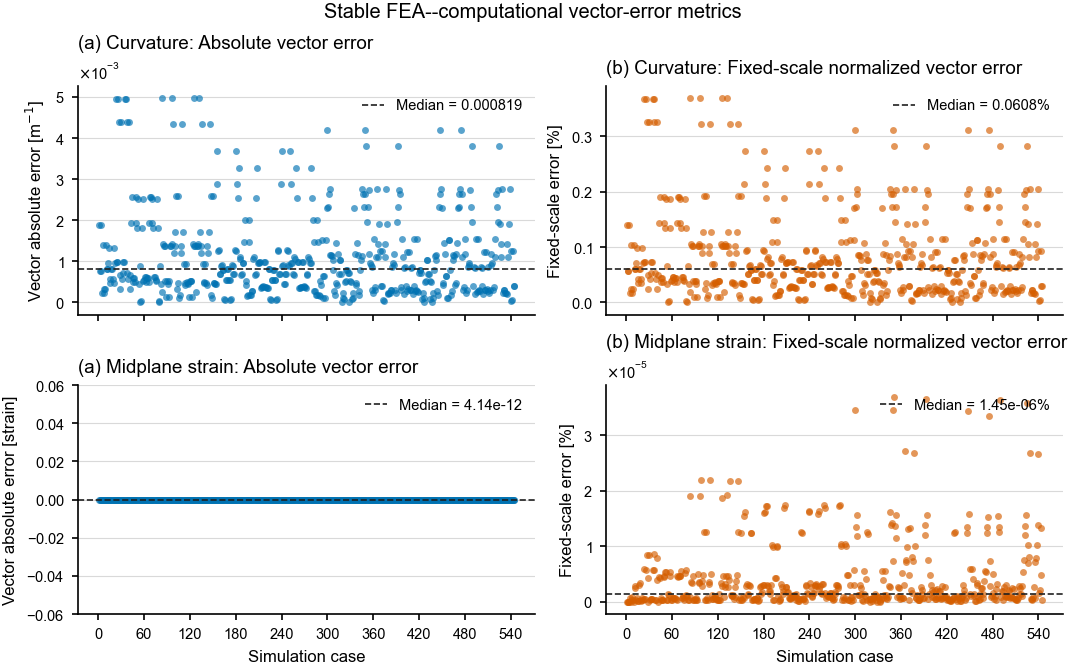

In [8]:
# ============================================================
# STABLE ERROR METRICS: CURVATURE AND MIDPLANE STRAIN
# ============================================================
# Headline relative metrics use a fixed response scale.  Conventional error /
# reference is retained nowhere in the plots because it is undefined or highly
# unstable near a physically small reference response.

RESPONSE_GROUPS = {
    "Curvature": {
        "unit": r"m$^{-1}$",
        "components": {"K11": ("K_11", "Comp_K_11"), "K22": ("K_22", "Comp_K_22"),
                       "K12": ("K_12", "Comp_K_12")},
    },
    "Midplane strain": {
        "unit": "strain",
        "components": {"e011": ("e0_11", "Comp_e0_11"), "e022": ("e0_22", "Comp_e0_22"),
                       "e012": ("e0_12", "Comp_e0_12")},
    },
}

metric_df = response_df.copy()
summary_rows = []
for group_name, group in RESPONSE_GROUPS.items():
    available = {name: columns for name, columns in group["components"].items()
                 if set(columns).issubset(metric_df.columns)}
    if not available:
        continue
    for component, (reference_column, prediction_column) in available.items():
        absolute = (metric_df[reference_column] - metric_df[prediction_column]).abs()
        scale = fixed_response_scale(metric_df[reference_column], metric_df[prediction_column])
        symmetric_denominator = metric_df[reference_column].abs() + metric_df[prediction_column].abs()
        smape = 200 * absolute / symmetric_denominator.where(symmetric_denominator > np.finfo(float).eps)
        prefix = f"{group_name}_{component}"
        metric_df[f"{prefix}_AbsoluteError"] = absolute
        metric_df[f"{prefix}_FixedScaleErrorPercent"] = 100 * absolute / scale
        metric_df[f"{prefix}_sMAPE"] = smape
        summary_rows.append({
            "Response": group_name,
            "Component": component,
            "Fixed scale": scale,
            "MAE": absolute.mean(),
            "Median fixed-scale error [%]": metric_df[f"{prefix}_FixedScaleErrorPercent"].median(),
            "Median sMAPE [%]": smape.median(),
        })

    reference_matrix = np.column_stack([metric_df[columns[0]] for columns in available.values()])
    prediction_matrix = np.column_stack([metric_df[columns[1]] for columns in available.values()])
    reference_magnitude = np.linalg.norm(reference_matrix, axis=1)
    prediction_magnitude = np.linalg.norm(prediction_matrix, axis=1)
    absolute_vector_error = np.linalg.norm(reference_matrix - prediction_matrix, axis=1)
    vector_scale = fixed_response_scale(reference_magnitude, prediction_magnitude)
    metric_df[f"{group_name}_VectorAbsoluteError"] = absolute_vector_error
    metric_df[f"{group_name}_VectorFixedScaleErrorPercent"] = 100 * absolute_vector_error / vector_scale

error_summary = pd.DataFrame(summary_rows)
display(error_summary.style.format({"Fixed scale": "{:.4g}", "MAE": "{:.4g}",
                                    "Median fixed-scale error [%]": "{:.3g}", "Median sMAPE [%]": "{:.3g}"}))

metric_case_id = case_numbers(metric_df)
fig, axes = plt.subplots(2, 2, figsize=(7.15, 4.5), sharex=True, layout="constrained")
for row, (group_name, group) in enumerate(RESPONSE_GROUPS.items()):
    absolute_column = f"{group_name}_VectorAbsoluteError"
    normalized_column = f"{group_name}_VectorFixedScaleErrorPercent"
    values = [(absolute_column, f"Vector absolute error [{group['unit']}]", "Absolute vector error", JOURNAL_COLORS["blue"]),
              (normalized_column, "Fixed-scale error [%]", "Fixed-scale normalized vector error", JOURNAL_COLORS["red"])]
    for ax, (column, ylabel, title, color), panel in zip(axes[row], values, ["(a)", "(b)"]):
        series = metric_df[column]
        median = series.median()
        ax.scatter(metric_case_id, series, s=11, alpha=0.65, color=color, linewidths=0, rasterized=True, zorder=2)
        ax.axhline(median, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.8,
                   label=f"Median = {median:.3g}{'%' if '%' in ylabel else ''}")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{panel} {group_name}: {title}", loc="left")
        set_linear_y_limits(ax, series, include_zero=True)
        apply_axis_style(ax, integer_x=True)
        ax.legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("Simulation case")
fig.suptitle("Stable FEA--computational vector-error metrics")
plt.show()


,Response,Component,Threshold,ExcludedNearZeroCases,TotalCases
0,Curvature,K11,1.000000e-05,0,545
1,Curvature,K12,1.000000e-05,120,545
2,Curvature,K22,1.000000e-05,0,545
3,Midplane strain,e011,1.000000e-08,0,545
4,Midplane strain,e012,2.000000e-10,545,545
5,Midplane strain,e022,1.000000e-08,0,545


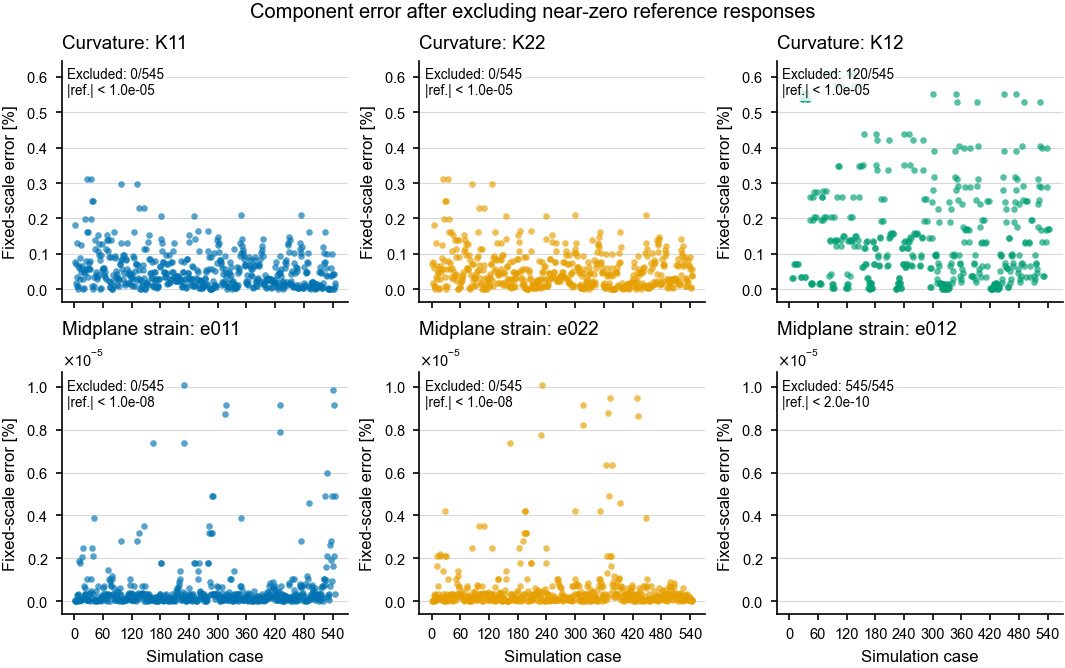

In [9]:
# ============================================================
# COMPONENT ERRORS EXCLUDING NEAR-ZERO REFERENCE RESPONSES
# ============================================================
# A near-zero reference cannot support an informative relative comparison.
# Such observations are excluded (not reassigned an error of zero), preventing
# a visually misleading reduction in the reported error.

COMPONENT_ZERO_THRESHOLDS = {
    # 0.01 microstrain = 1e-8 strain; use this consistently for all strain components.
    "e0_11": 1e-8, "e0_22": 1e-8, "e0_12": 1e-8,
    "K_11": 1e-5, "K_22": 1e-5, "K_12": 1e-5,
}
component_rows = []
for group_name, group in RESPONSE_GROUPS.items():
    for component_name, (reference_column, prediction_column) in group["components"].items():
        threshold = COMPONENT_ZERO_THRESHOLDS[reference_column]
        scale = fixed_response_scale(metric_df[reference_column], metric_df[prediction_column])
        near_zero = metric_df[reference_column].abs() < threshold
        normalized_error = 100 * (metric_df[reference_column] - metric_df[prediction_column]).abs() / scale
        component_rows.append(pd.DataFrame({
            "Response": group_name,
            "Component": component_name,
            "Case": case_numbers(metric_df),
            "Threshold": threshold,
            "NearZeroReference": near_zero,
            "FixedScaleErrorPercent": normalized_error.mask(near_zero),
        }))

near_zero_component_errors = pd.concat(component_rows, ignore_index=True)
near_zero_summary = (near_zero_component_errors.groupby(["Response", "Component"], as_index=False)
                     .agg(Threshold=("Threshold", "first"),
                          ExcludedNearZeroCases=("NearZeroReference", "sum"),
                          TotalCases=("Case", "size")))
display(near_zero_summary)

fig, axes = plt.subplots(2, 3, figsize=(7.15, 4.5), sharex=True, layout="constrained")
for row, group_name in enumerate(RESPONSE_GROUPS):
    group_data = near_zero_component_errors[near_zero_component_errors["Response"] == group_name]
    valid_values = group_data["FixedScaleErrorPercent"].dropna()
    group_limits = padded_limits(valid_values, include_zero=True)
    for column, component_name in enumerate(RESPONSE_GROUPS[group_name]["components"]):
        ax = axes[row, column]
        component_data = group_data[group_data["Component"] == component_name]
        valid = component_data.dropna(subset=["FixedScaleErrorPercent"])
        ax.scatter(valid["Case"], valid["FixedScaleErrorPercent"], s=10, alpha=0.66,
                   color=PLY_COLORS[column], linewidths=0, rasterized=True, zorder=2)
        ax.set_ylim(group_limits)
        ax.set_title(f"{group_name}: {component_name}", loc="left")
        ax.set_ylabel("Fixed-scale error [%]")
        apply_axis_style(ax, integer_x=True)
        excluded = int(component_data["NearZeroReference"].sum())
        threshold = component_data["Threshold"].iloc[0]
        ax.text(0.02, 0.97, f"Excluded: {excluded}/{len(component_data)}\n|ref.| < {threshold:.1e}",
                transform=ax.transAxes, va="top", ha="left", fontsize=6.5,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82, "pad": 1.5})
for ax in axes[-1]:
    ax.set_xlabel("Simulation case")
fig.suptitle("Component error after excluding near-zero reference responses")
plt.show()


,Component,Near-zero threshold,Fixed response scale,Excluded cases,Included cases
0,e0_11,1.0e-08,0.000284,0,545
1,e0_22,1.0e-08,0.000284,0,545
2,e0_12,2.0e-10,3.547e-11,545,0
3,K_11,1.0e-05,0.9745,0,545
4,K_22,1.0e-05,0.9745,0,545
5,K_12,1.0e-05,0.6105,120,425


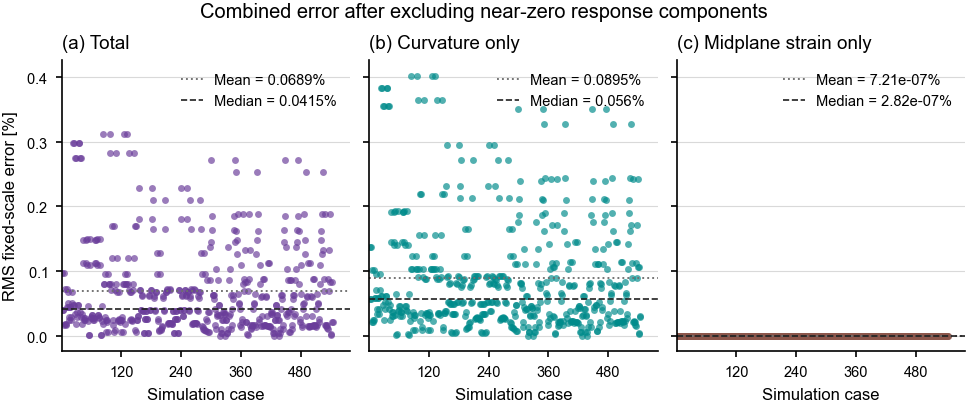

,mean,median,max
TotalRMSFixedScaleErrorPercent,0.06889,0.04154,0.3121
CurvatureRMSFixedScaleErrorPercent,0.08955,0.05597,0.4029
StrainRMSFixedScaleErrorPercent,7.214e-07,2.817e-07,8.983e-06


In [ ]:
# ============================================================
# COMBINED PERCENT ERROR WITH COMPONENT-SPECIFIC ZERO THRESHOLDS
# ============================================================
# Each retained component uses conventional reference-relative percent error.
# Components below their physical near-zero threshold are excluded from that
# case's RMS rather than counted as zero error.

combined_df = response_df.copy()
STRAIN_COMPONENTS = ["e0_11", "e0_22", "e0_12"]
CURVATURE_COMPONENTS = ["K_11", "K_22", "K_12"]
ALL_COMPONENTS = STRAIN_COMPONENTS + CURVATURE_COMPONENTS
percent_error_columns = {}
threshold_rows = []

for component in ALL_COMPONENTS:
    reference = combined_df[component]
    prediction = combined_df[f"Comp_{component}"]
    threshold = COMPONENT_ZERO_THRESHOLDS[component]
    valid = reference.abs() >= threshold
    column = f"PercentError_{component}"
    combined_df[column] = (100 * (reference - prediction).abs() / reference.abs()).where(valid)
    percent_error_columns[component] = column
    threshold_rows.append({
        "Component": component,
        "Near-zero threshold": threshold,
        "Excluded cases": int((~valid).sum()),
        "Included cases": int(valid.sum()),
    })


def rms_over_available_components(components):
    values = combined_df[[percent_error_columns[component] for component in components]].to_numpy(dtype=float)
    valid_count = np.sum(np.isfinite(values), axis=1)
    squared_sum = np.nansum(values ** 2, axis=1)
    return np.where(valid_count > 0, np.sqrt(squared_sum / valid_count), np.nan)


combined_df["StrainRMSPercentError"] = rms_over_available_components(STRAIN_COMPONENTS)
combined_df["CurvatureRMSPercentError"] = rms_over_available_components(CURVATURE_COMPONENTS)
combined_df["TotalRMSPercentError"] = rms_over_available_components(ALL_COMPONENTS)

component_threshold_summary = pd.DataFrame(threshold_rows)
display(component_threshold_summary.style.format({"Near-zero threshold": "{:.1e}"}))

# Dedicated palette for combined metrics; none repeats the six standalone
# absolute-error component colours.
COMBINED_ERROR_COLORS = {"total": "#6A3D9A", "curvature": "#008B8B", "strain": "#8C564B"}
combined_error_plots = [
    ("TotalRMSPercentError", "Total", COMBINED_ERROR_COLORS["total"]),
    ("CurvatureRMSPercentError", "Curvature only", COMBINED_ERROR_COLORS["curvature"]),
    ("StrainRMSPercentError", "Midplane strain only", COMBINED_ERROR_COLORS["strain"]),
]
combined_values = combined_df[[item[0] for item in combined_error_plots]].to_numpy()
combined_limits = padded_limits(combined_values, include_zero=True)
case_id = case_numbers(combined_df)

# Match the physical panel size and column spacing of the 2x3 standalone
# absolute-error figure, allowing this row to stack directly beneath it.
fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.75), sharex=True, sharey=True)
fig.subplots_adjust(left=0.07, right=0.994, bottom=0.16, top=0.85, wspace=0.29)
for ax, (column, title, color), panel in zip(axes, combined_error_plots, ["(a)", "(b)", "(c)"]):
    values = combined_df[column]
    mean = values.mean()
    median = values.median()
    ax.scatter(case_id, values, s=11, alpha=0.68, color=color, linewidths=0, rasterized=True, zorder=2)
    ax.axhline(mean, color=JOURNAL_COLORS["gray"], linestyle=":", linewidth=0.9,
               label=f"Mean = {mean:.3g}%")
    ax.axhline(median, color=JOURNAL_COLORS["black"], linestyle="--", linewidth=0.8,
               label=f"Median = {median:.3g}%")
    ax.set_ylim(combined_limits)
    ax.set_xlabel("Simulation case")
    ax.set_title(f"{panel} {title}", loc="left")
    apply_axis_style(ax, integer_x=True)
    ax.set_xticks(np.arange(120, len(combined_df) + 1, 120))
    ax.set_xlim(0, len(combined_df) + 35)
    ax.legend(loc="upper right")
axes[0].set_ylabel("RMS percent error [%]")
fig.suptitle("Combined percent error after excluding near-zero response components")
plt.show()

combined_error_summary = combined_df[[item[0] for item in combined_error_plots]].agg(["mean", "median", "max"]).T
display(combined_error_summary.style.format("{:.4g}"))


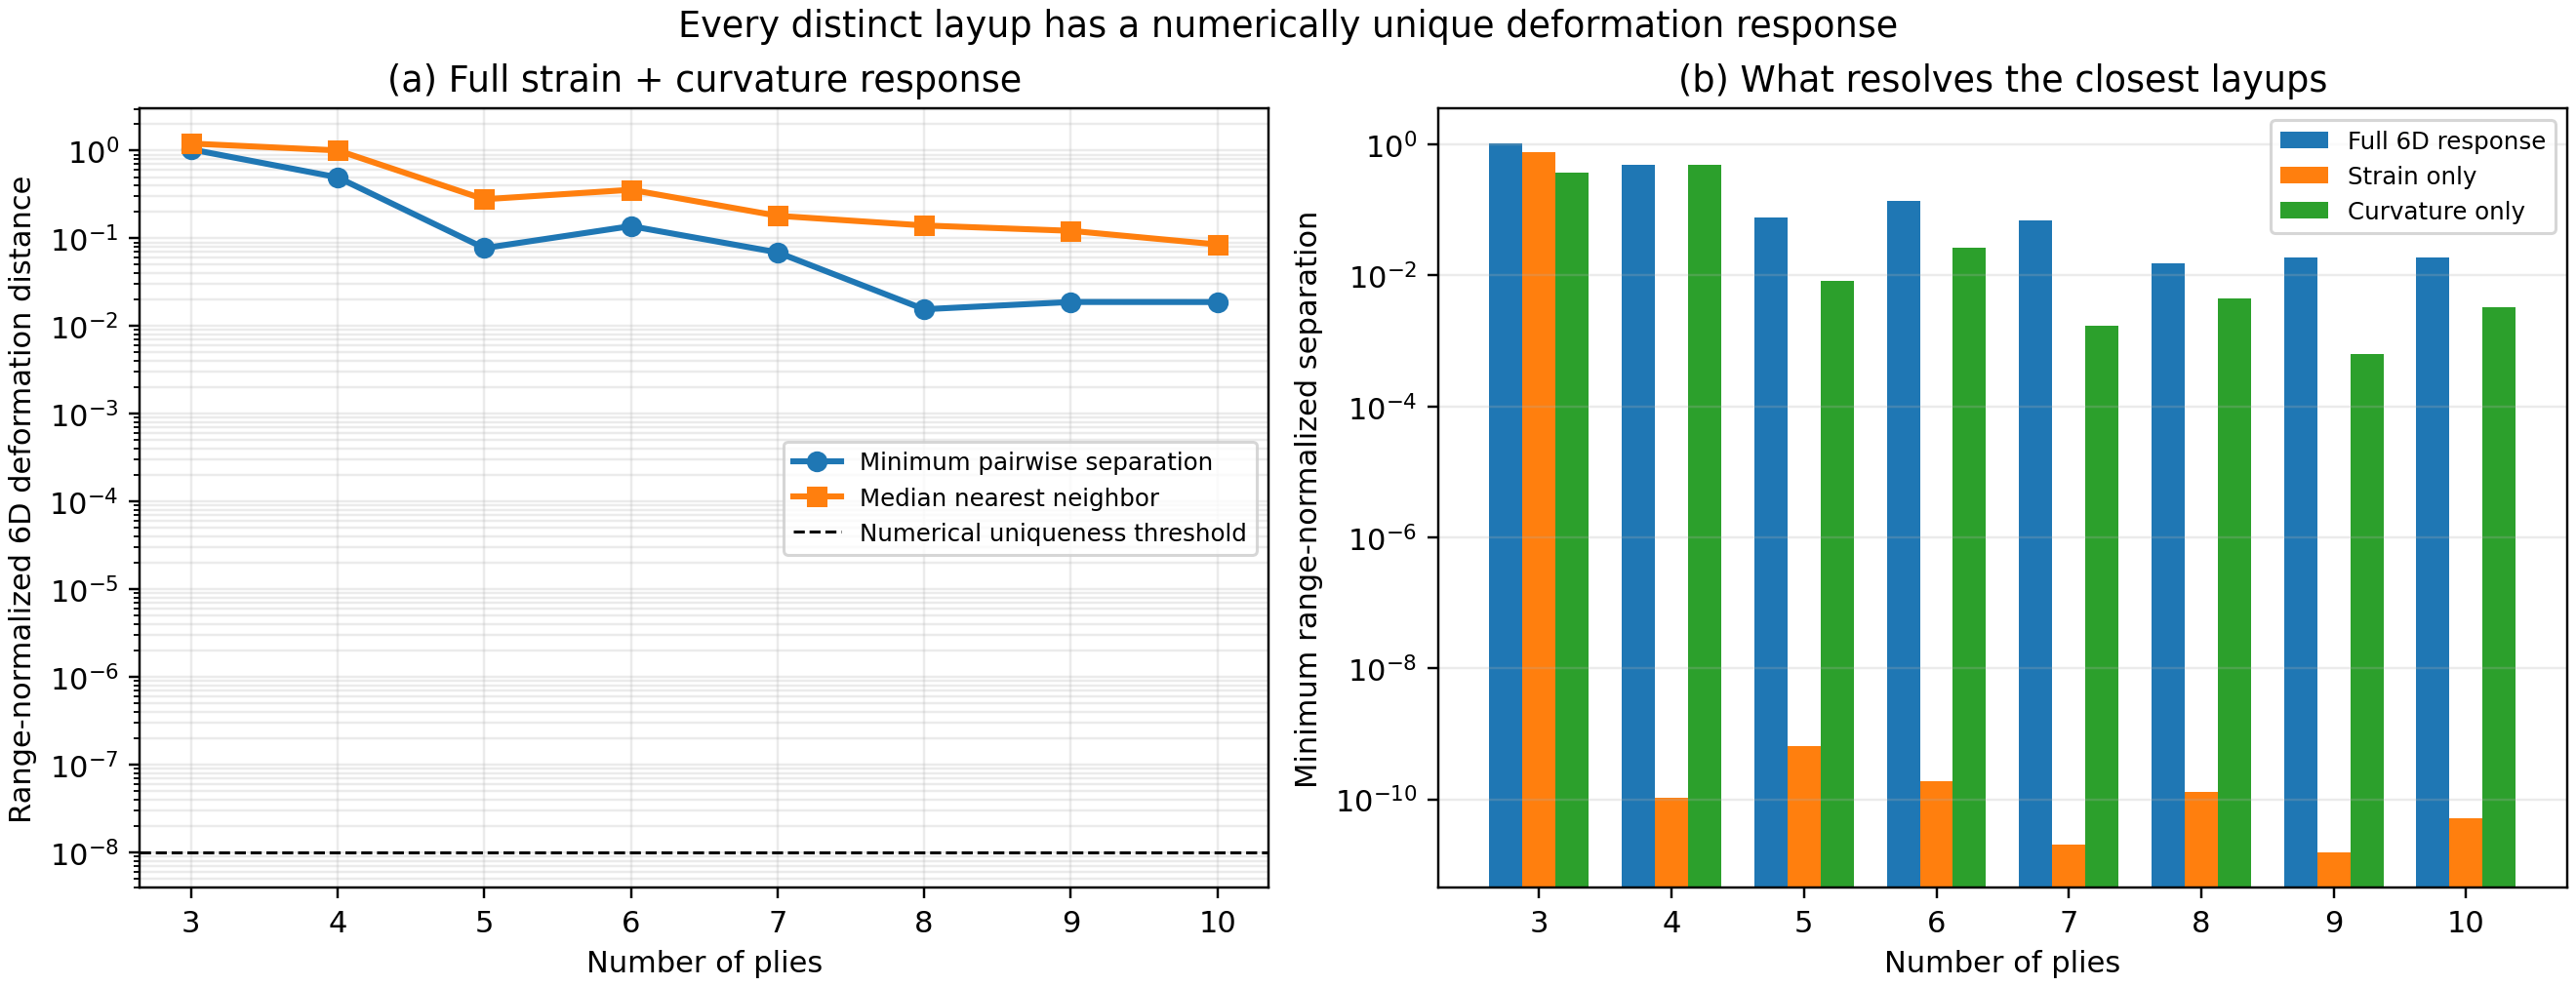

,Ply count,Dataset rows,Distinct layups,Repeated input rows,Unique 6D deformations,Minimum 6D separation,Median nearest-neighbor separation,Minimum strain-only separation,Minimum curvature-only separation,Closest distinct layup A,Closest distinct layup B
0,3,4,4,0,4,1.033831,1.205215,7.663618e-01,0.370296,[90/0/90],[90/90/90]
1,4,6,6,0,6,0.495970,1.006374,1.039652e-10,0.495970,[0/90/90/0],[90/0/0/90]
2,5,12,12,0,12,0.077372,0.279053,6.506065e-10,0.008329,[90/0/0/0/90],[90/0/90/0/90]
3,6,20,20,0,20,0.137858,0.357974,1.861684e-10,0.026814,[90/0/0/0/0/90],[90/0/90/90/0/90]
4,7,40,40,0,40,0.069187,0.180872,2.033382e-11,0.001722,[90/0/0/90/0/0/90],[90/0/90/0/90/0/90]
5,8,70,70,0,70,0.015551,0.140289,1.301131e-10,0.004475,[45/90/-45/0/0/-45/90/45],[90/45/0/-45/-45/0/45/90]
6,9,140,140,0,140,0.018810,0.121890,1.550569e-11,0.000620,[-45/90/45/0/90/0/45/90/-45],[90/-45/0/45/90/45/0/-45/90]
7,10,253,252,2,252,0.018777,0.085169,5.189928e-11,0.003313,[-45/90/45/0/0/0/0/45/90/-45],[90/-45/0/45/0/0/45/0/-45/90]


,Ply count,Pair member,Curvature-space distance (m^-1),Layup,e0_11 (microstrain),e0_22 (microstrain),e0_12 (microstrain),K_11 (m^-1),K_22 (m^-1),"K_12 (m^-1, engineering)"
0,3,A,0.527536,[0/0/0],-12.500000,750.000000,1.292470e-16,0.002932,-1.592434,1.647009e-20
1,3,B,0.527536,[0/90/0],28.870704,101.934424,3.044484e-17,0.001041,-1.064901,-1.176435e-20
2,4,A,0.684887,[-45/45/45/-45],55.393836,55.393836,1.712820e-07,-0.283825,-0.283825,-5.587778e-01
3,4,B,0.684887,[0/90/90/0],55.393836,55.393836,1.436077e-17,-0.003270,-0.563337,-4.235165e-20
4,5,A,0.013313,[0/90/0/90/0],38.065620,79.539709,5.514537e-17,-0.012090,-0.366625,-3.764591e-20
5,5,B,0.013313,[0/90/90/90/0],79.539709,38.065620,2.872155e-16,-0.012888,-0.353336,-9.411477e-20
6,6,A,0.042893,[0/90/0/0/90/0],28.870704,101.934424,3.794117e-16,-0.021129,-0.291444,2.258755e-19
7,6,B,0.042893,[0/90/90/90/90/0],101.934424,28.870704,1.860438e-16,-0.027588,-0.249040,-4.517509e-19
8,7,A,0.002757,[0/90/90/0/90/90/0],71.702890,42.512253,3.498285e-16,-0.046249,-0.189345,-1.694066e-19
9,7,B,0.002757,[0/90/90/90/90/90/0],122.830975,23.090372,-3.676358e-17,-0.047683,-0.186990,-3.764591e-20


In [11]:
# Deformation uniqueness by ply count
# Uses the 130 GPa computational response columns (Comp_e0_* and Comp_K_*),
# after collapsing layups that differ only by a 90-degree in-plane rotation.
# Regenerate the PNG/CSV/Markdown assets after the comparison dataset changes.
%matplotlib inline

from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image, display

plotting_dir = Path.cwd()
if not (plotting_dir / 'generate_deformation_uniqueness.py').exists():
    plotting_dir = Path('Plotting')

script_path = plotting_dir / 'generate_deformation_uniqueness.py'
# Run the file-export script in a separate process: it uses the Agg backend
# for PNG export and must not change this notebook's inline backend.
subprocess.run([sys.executable, str(script_path)], check=True)
display(Image(filename=str(plotting_dir / 'ply_count_deformation_uniqueness.png')))
display(pd.read_csv(plotting_dir / 'ply_count_deformation_uniqueness.csv'))

# All-pairs raw 3-D curvature-space separation summary for each ply count.
# The min/median/mean exclude rotation-equivalent layups and are in m^-1.
display(pd.read_csv(plotting_dir / 'curvature_space_pairwise_separation_summary.csv'))

# The two rotation-distinct layups closest in raw 3-D curvature space at each ply count.
# The repeated distance is their Euclidean separation in m^-1; strain is
# shown in microstrain and K_12 is the engineering twisting curvature.
display(pd.read_csv(plotting_dir / 'closest_layup_deformation_components.csv'))


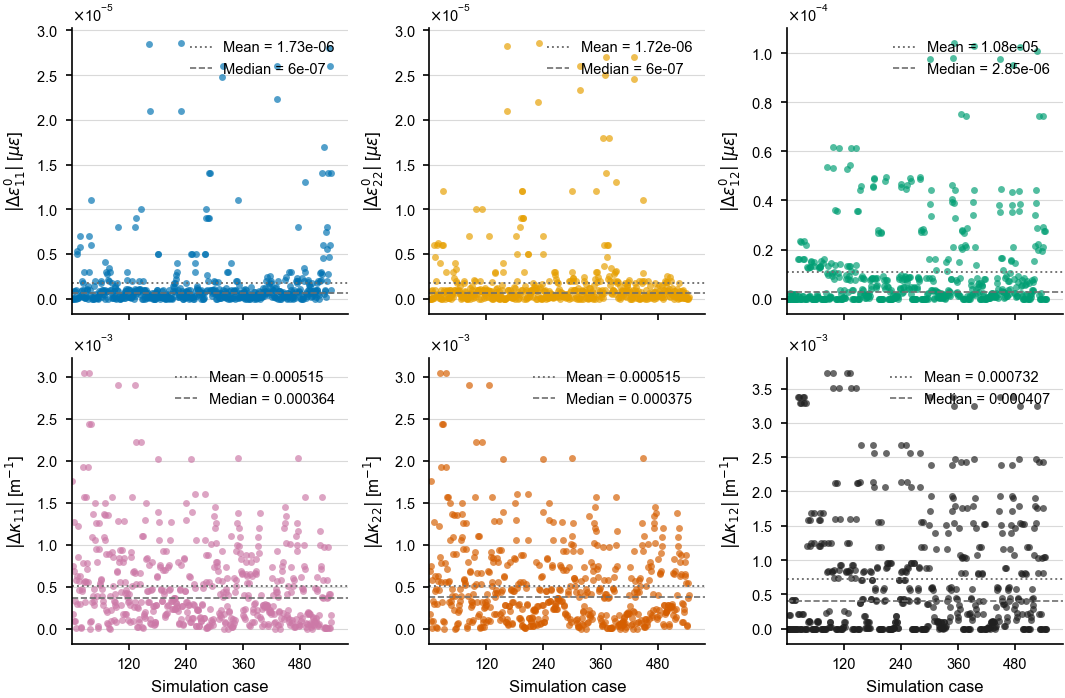

In [12]:
# ============================================================
# STANDALONE ABSOLUTE ERROR FOR EVERY RESPONSE COMPONENT
# ============================================================
# Each panel is intentionally independent: no normalization, aggregation,
# or shared vertical scale obscures the error range of a component.

ABSOLUTE_ERROR_COMPONENTS = [
    ("e0_11", "Comp_e0_11", r"$|\Delta \epsilon^0_{11}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["blue"]),
    ("e0_22", "Comp_e0_22", r"$|\Delta \epsilon^0_{22}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["orange"]),
    ("e0_12", "Comp_e0_12", r"$|\Delta \epsilon^0_{12}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["green"]),
    ("K_11", "Comp_K_11", r"$|\Delta \kappa_{11}|$ [m$^{-1}$]", JOURNAL_COLORS["purple"]),
    ("K_22", "Comp_K_22", r"$|\Delta \kappa_{22}|$ [m$^{-1}$]", JOURNAL_COLORS["red"]),
    ("K_12", "Comp_K_12", r"$|\Delta \kappa_{12}|$ [m$^{-1}$]", JOURNAL_COLORS["black"]),
]

fig, axes = plt.subplots(2, 3, figsize=(7.15, 4.7), sharex=True, layout="constrained")
case_id = case_numbers(response_df)

for ax, (fea_column, comp_column, ylabel, color) in zip(axes.flat, ABSOLUTE_ERROR_COMPONENTS):
    absolute_error = (response_df[fea_column] - response_df[comp_column]).abs()
    plotted_error = absolute_error * 1e6 if fea_column.startswith("e0_") else absolute_error
    mean = plotted_error.mean()
    median = plotted_error.median()
    ax.scatter(case_id, plotted_error, s=11, alpha=0.68, color=color,
               linewidths=0, rasterized=True, zorder=2)
    ax.axhline(mean, color=JOURNAL_COLORS["gray"], linestyle=":", linewidth=0.9,
               label=f"Mean = {mean:.3g}")
    ax.axhline(median, color=JOURNAL_COLORS["gray"], linestyle="--", linewidth=0.8,
               label=f"Median = {median:.3g}")
    ax.set_ylabel(ylabel)
    set_linear_y_limits(ax, plotted_error, include_zero=True)
    apply_axis_style(ax, integer_x=True)
    if fea_column.startswith("e0_"):
        # Strain errors are O(10^-11)--O(10^-10); show a denser scientific scale.
        ax.yaxis.set_major_locator(MaxNLocator(nbins=7))
        strain_formatter = ScalarFormatter(useMathText=True)
        strain_formatter.set_powerlimits((-1, 1))
        ax.yaxis.set_major_formatter(strain_formatter)
    ax.set_xticks(np.arange(120, len(response_df) + 1, 120))
    ax.set_xlim(0, len(response_df) + 35)
    ax.legend(loc="upper right")

for ax in axes[-1]:
    ax.set_xlabel("Simulation case")
plt.show()


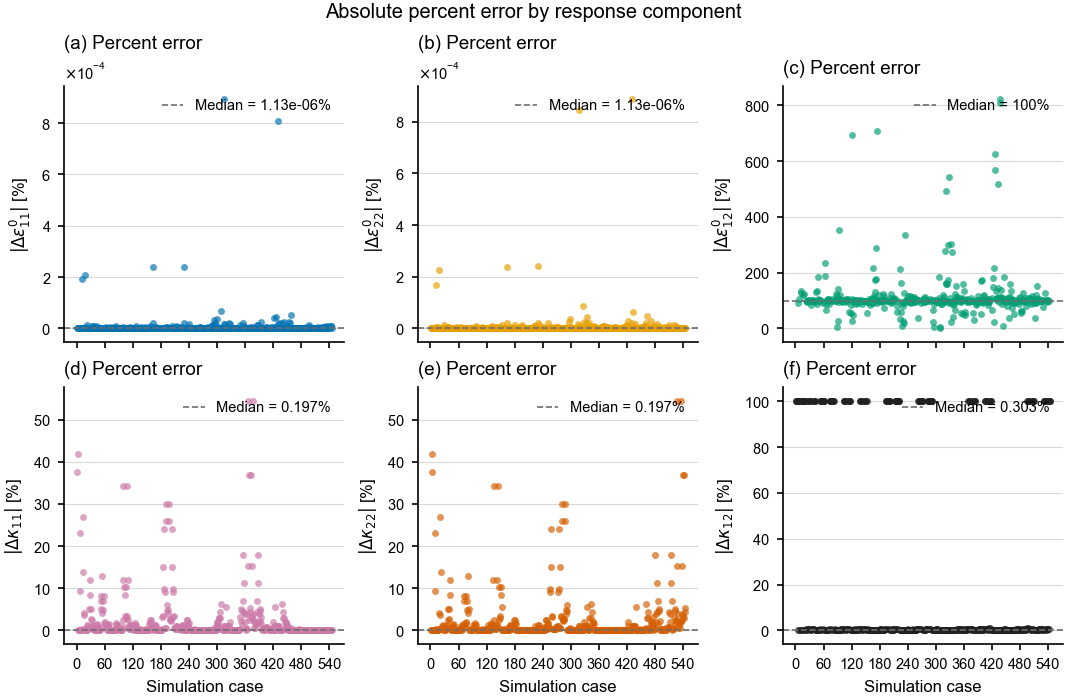

In [13]:
# ============================================================
# STANDALONE PERCENT ERROR FOR EVERY RESPONSE COMPONENT
# ============================================================
# Percent error is reported as |computational - Abaqus| / |Abaqus| x 100.
# Cases with an exactly/nearly zero Abaqus response are omitted because a
# percentage relative to zero is undefined.

PERCENT_ERROR_COMPONENTS = [
    ("e0_11", r"$|\Delta \epsilon^0_{11}|$ [%]", JOURNAL_COLORS["blue"]),
    ("e0_22", r"$|\Delta \epsilon^0_{22}|$ [%]", JOURNAL_COLORS["orange"]),
    ("e0_12", r"$|\Delta \epsilon^0_{12}|$ [%]", JOURNAL_COLORS["green"]),
    ("K_11", r"$|\Delta \kappa_{11}|$ [%]", JOURNAL_COLORS["purple"]),
    ("K_22", r"$|\Delta \kappa_{22}|$ [%]", JOURNAL_COLORS["red"]),
    ("K_12", r"$|\Delta \kappa_{12}|$ [%]", JOURNAL_COLORS["black"]),
]

fig, axes = plt.subplots(2, 3, figsize=(7.15, 4.7), sharex=True, layout="constrained")
case_id = case_numbers(response_df)

for ax, (component, ylabel, color), panel in zip(
    axes.flat, PERCENT_ERROR_COMPONENTS, ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
):
    percent_error = response_df[f"PercentError_{component}"].abs()
    valid = percent_error.notna() & np.isfinite(percent_error)
    median = percent_error[valid].median()
    ax.scatter(case_id[valid], percent_error[valid], s=11, alpha=0.68, color=color,
               linewidths=0, rasterized=True, zorder=2)
    ax.axhline(median, color=JOURNAL_COLORS["gray"], linestyle="--", linewidth=0.8,
               label=f"Median = {median:.3g}%")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{panel} Percent error", loc="left")
    set_linear_y_limits(ax, percent_error[valid], include_zero=True)
    apply_axis_style(ax, integer_x=True)
    ax.legend(loc="upper right")

for ax in axes[-1]:
    ax.set_xlabel("Simulation case")
fig.suptitle("Absolute percent error by response component")
plt.show()


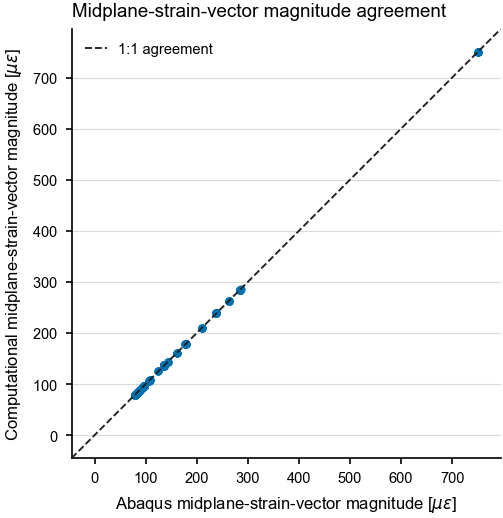

,Identity plot,Unit,Cases,MAE,RMSE,Bias (computational - Abaqus),Maximum absolute error,Identity R-squared,Pearson r,OLS slope,OLS intercept
0,Curvature-vector magnitude,m$^{-1}$,545,0.0007473,0.001169,-0.0006333,0.004451,0.99998899,0.99999724,0.99848935,0.0002665
1,Midplane-strain-vector magnitude,$\mu\varepsilon$,545,2.56e-06,5.169e-06,-2.279e-06,2.792e-05,1.00000000,1.00000000,1.00000000,-1.831e-06


In [14]:
# ============================================================
# MIDPLANE-STRAIN VECTOR IDENTITY PLOT
# ============================================================
# This matches the curvature-vector identity figure: each point is the
# Euclidean magnitude of the three midplane-strain components.

from IPython.display import display

STRAIN_COLUMNS = ["e0_11", "e0_22", "e0_12"]
abaqus_strain_magnitude = np.linalg.norm(response_df[STRAIN_COLUMNS].to_numpy(dtype=float), axis=1) * 1e6
computational_strain_magnitude = np.linalg.norm(
    response_df[[f"Comp_{component}" for component in STRAIN_COLUMNS]].to_numpy(dtype=float), axis=1
) * 1e6
identity_limits = padded_limits(
    np.concatenate([abaqus_strain_magnitude, computational_strain_magnitude]), include_zero=True
)

fig, ax = plt.subplots(figsize=(3.5, 3.5), layout="constrained")
ax.scatter(abaqus_strain_magnitude, computational_strain_magnitude, s=15, alpha=0.70,
           color=JOURNAL_COLORS["blue"], linewidths=0, rasterized=True, zorder=2)
ax.plot(identity_limits, identity_limits, color=JOURNAL_COLORS["black"], linestyle="--",
        linewidth=0.9, label="1:1 agreement", zorder=3)
ax.set_xlim(identity_limits)
ax.set_ylim(identity_limits)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"Abaqus midplane-strain-vector magnitude [$\mu\varepsilon$]")
ax.set_ylabel(r"Computational midplane-strain-vector magnitude [$\mu\varepsilon$]")
ax.set_title("Midplane-strain-vector magnitude agreement", loc="left")
apply_axis_style(ax)
ax.legend(loc="upper left")
plt.show()

# Agreement metrics for the curvature and strain identity plots.
# Identity R-squared is evaluated against the identity relation, y = x.
def identity_metrics(reference, prediction, name, unit):
    difference = prediction - reference
    slope, intercept = np.polyfit(reference, prediction, 1)
    identity_r_squared = 1 - np.sum(difference ** 2) / np.sum((reference - reference.mean()) ** 2)
    return {
        "Identity plot": name, "Unit": unit, "Cases": len(reference),
        "MAE": np.mean(np.abs(difference)),
        "RMSE": np.sqrt(np.mean(difference ** 2)),
        "Bias (computational - Abaqus)": np.mean(difference),
        "Maximum absolute error": np.max(np.abs(difference)),
        "Identity R-squared": identity_r_squared,
        "Pearson r": np.corrcoef(reference, prediction)[0, 1],
        "OLS slope": slope, "OLS intercept": intercept,
    }

CURVATURE_IDENTITY_COLUMNS = ["K_11", "K_22", "K_12"]
abaqus_curvature_magnitude = np.linalg.norm(response_df[CURVATURE_IDENTITY_COLUMNS].to_numpy(dtype=float), axis=1)
computational_curvature_magnitude = np.linalg.norm(
    response_df[[f"Comp_{component}" for component in CURVATURE_IDENTITY_COLUMNS]].to_numpy(dtype=float), axis=1
)
identity_metrics_table = pd.DataFrame([
    identity_metrics(abaqus_curvature_magnitude, computational_curvature_magnitude,
                     "Curvature-vector magnitude", r"m$^{-1}$"),
    identity_metrics(abaqus_strain_magnitude, computational_strain_magnitude,
                     "Midplane-strain-vector magnitude", r"$\mu\varepsilon$"),
])
display(identity_metrics_table.style.format({
    "MAE": "{:.4g}", "RMSE": "{:.4g}", "Bias (computational - Abaqus)": "{:.4g}",
    "Maximum absolute error": "{:.4g}", "Identity R-squared": "{:.8f}",
    "Pearson r": "{:.8f}", "OLS slope": "{:.8f}", "OLS intercept": "{:.4g}",
}))


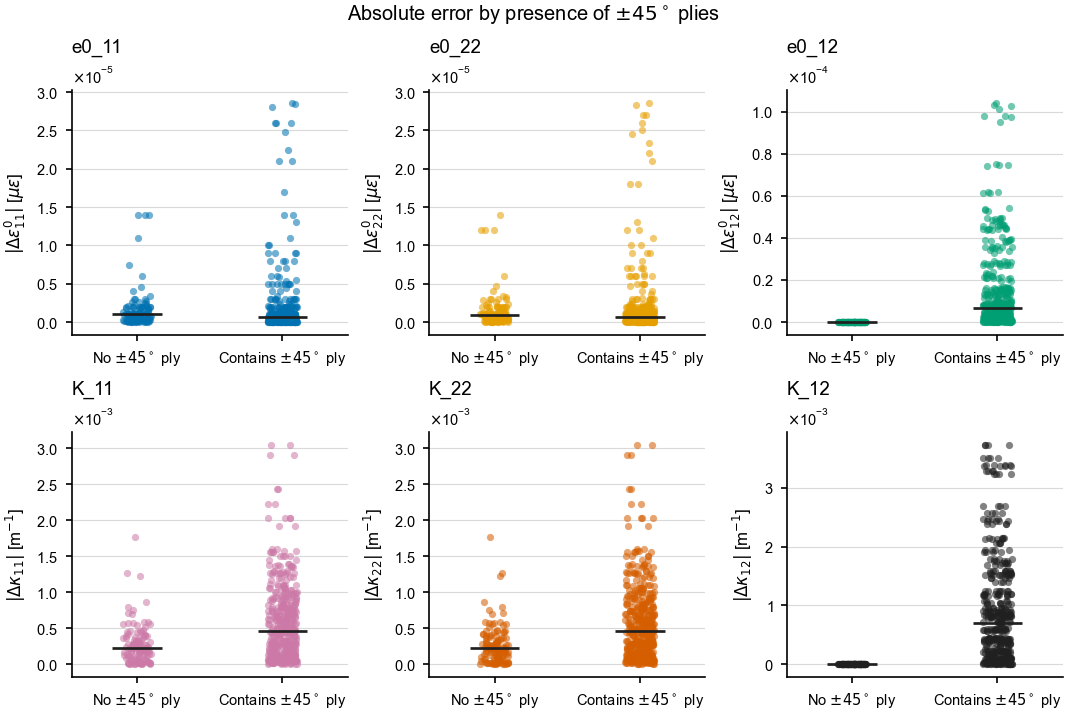

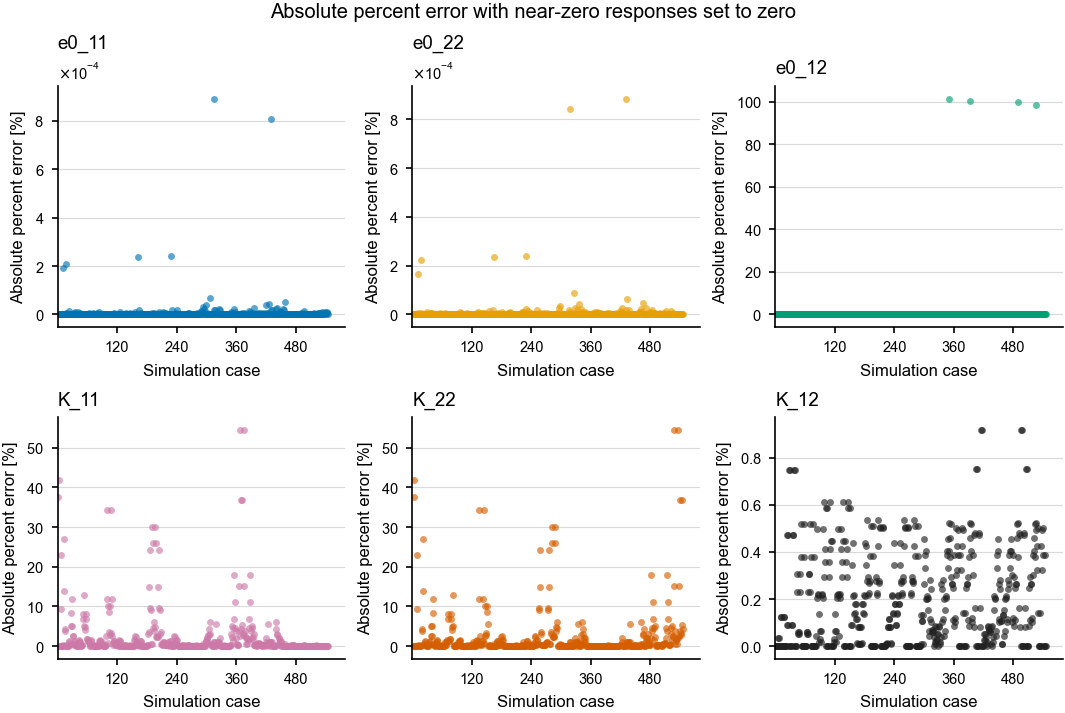

,Component,Near-zero threshold,Cases set to zero
0,e0_11,1.0e-08,0
1,e0_22,1.0e-08,0
2,e0_12,1.0e-10,541
3,K_11,1.0e-05,0
4,K_22,1.0e-05,0
5,K_12,1.0e-05,120


In [15]:
# ============================================================
# ERROR BY PRESENCE OF +/-45-DEGREE PLIES
# ============================================================
# A case belongs to the off-axis group when its layup includes +45 or -45.
# The percent-error plot is ungrouped.  Its percent error is set to zero
# when the corresponding Abaqus component is physically near zero.

from IPython.display import display

GROUPED_ERROR_COMPONENTS = [
    ("e0_11", r"$|\Delta \epsilon^0_{11}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["blue"]),
    ("e0_22", r"$|\Delta \epsilon^0_{22}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["orange"]),
    ("e0_12", r"$|\Delta \epsilon^0_{12}|$ [$\mu\varepsilon$]", JOURNAL_COLORS["green"]),
    ("K_11", r"$|\Delta \kappa_{11}|$ [m$^{-1}$]", JOURNAL_COLORS["purple"]),
    ("K_22", r"$|\Delta \kappa_{22}|$ [m$^{-1}$]", JOURNAL_COLORS["red"]),
    ("K_12", r"$|\Delta \kappa_{12}|$ [m$^{-1}$]", JOURNAL_COLORS["black"]),
]
GROUP_LABELS = [r"No $\pm45^\circ$ ply", r"Contains $\pm45^\circ$ ply"]
PERCENT_ERROR_ZERO_THRESHOLDS = {
    "e0_11": 1e-8, "e0_22": 1e-8, "e0_12": 1e-10,
    "K_11": 1e-5, "K_22": 1e-5, "K_12": 1e-5,
}

def layup_contains_off_axis_45(layup_text):
    angles = [float(angle) for angle in str(layup_text).strip().strip("[]").split("/")]
    return any(np.isclose(abs(angle), 45.0) for angle in angles)

grouped_error_df = response_df.copy()
grouped_error_df["ContainsOffAxis45"] = grouped_error_df["Layup"].apply(layup_contains_off_axis_45)

def grouped_error_panel(ax, values, ylabel, color, title):
    rng = np.random.default_rng(20260930)
    for group_index, contains_45 in enumerate([False, True]):
        group_values = values[grouped_error_df["ContainsOffAxis45"] == contains_45].dropna().to_numpy()
        jitter = rng.uniform(-0.10, 0.10, size=len(group_values))
        ax.scatter(group_index + jitter, group_values, s=12, alpha=0.56, color=color,
                   linewidths=0, rasterized=True, zorder=2)
        median = np.median(group_values)
        ax.hlines(median, group_index - 0.17, group_index + 0.17,
                  color=JOURNAL_COLORS["black"], linewidth=1.3, zorder=3)
    ax.set_xticks([0, 1], GROUP_LABELS)
    ax.set_xlim(-0.45, 1.45)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    set_linear_y_limits(ax, values, include_zero=True)
    apply_axis_style(ax)

# Absolute error: strain values are plotted in microstrain.
fig, axes = plt.subplots(2, 3, figsize=(7.15, 4.8), layout="constrained")
for ax, (component, ylabel, color) in zip(axes.flat, GROUPED_ERROR_COMPONENTS):
    absolute_error = (grouped_error_df[component] - grouped_error_df[f"Comp_{component}"]).abs()
    plotted_error = absolute_error * 1e6 if component.startswith("e0_") else absolute_error
    grouped_error_panel(ax, plotted_error, ylabel, color, component)
fig.suptitle(r"Absolute error by presence of $\pm45^\circ$ plies")
plt.show()

# Percent error: plot each case directly, with near-zero reference responses
# set to zero before calculating the visualized absolute percent error.
fig, axes = plt.subplots(2, 3, figsize=(7.15, 4.8), layout="constrained")
percent_error_zero_summary = []
for ax, (component, _, color) in zip(axes.flat, GROUPED_ERROR_COMPONENTS):
    reference_magnitude = grouped_error_df[component].abs()
    threshold = PERCENT_ERROR_ZERO_THRESHOLDS[component]
    absolute_percent_error = 100 * (grouped_error_df[component] - grouped_error_df[f"Comp_{component}"]).abs() / reference_magnitude
    stabilized_percent_error = absolute_percent_error.where(reference_magnitude >= threshold, 0.0)
    ax.scatter(case_numbers(grouped_error_df), stabilized_percent_error, s=11, alpha=0.64,
               color=color, linewidths=0, rasterized=True, zorder=2)
    ax.set_xlabel("Simulation case")
    ax.set_ylabel("Absolute percent error [%]")
    ax.set_title(component, loc="left")
    set_linear_y_limits(ax, stabilized_percent_error, include_zero=True)
    apply_axis_style(ax, integer_x=True)
    ax.set_xticks(np.arange(120, len(grouped_error_df) + 1, 120))
    ax.set_xlim(0, len(grouped_error_df) + 35)
    percent_error_zero_summary.append({
        "Component": component,
        "Near-zero threshold": threshold,
        "Cases set to zero": int((reference_magnitude < threshold).sum()),
    })
fig.suptitle("Absolute percent error with near-zero responses set to zero")
plt.show()

display(pd.DataFrame(percent_error_zero_summary).style.format({"Near-zero threshold": "{:.1e}"}))
